In [42]:

import pandas as pd 
import numpy as np 


#### Headline Result

Logistic regression fit on three ratio features achieved a **Recall@3 score of 0.824**, outperforming the persistence baseline of **0.527**.

| Model | Recall@3 | Average Precision (AP) |
|---|---:|---:|
| Logistic Regression (3 ratio features) | **0.824** | 0.438 |
| Persistence Baseline | 0.527 | 0.278 |

The logistic regression model improves Recall@3 by **0.297** over the persistence baseline.*

*this result is subject to further evaluation, performed below


# Predicting Traffic Slowdowns at Known Maritime Chokepoints

## Modeling Time-Series Data

According to Faouzi (2025), the general assumption of conditional independence of observations required by many standard machine learning algorithms such as the Naive Bayes is not suited for time series data, as the order of the values in the dataset is itself an important feature of observations, and correlation is expected. A recognized technique for adapting time-series for classification is to extract features from the chronological data to use as inputs for a standard classification model. If one variable is used from the time series the model is considered univariate, multiple variables is called multivariate. 

For this analysis a single variable was used, the total number of ships transiting a chokepoint on a given day, meaning the underlying dataset is univariate. Multiple features are calculated from the single variable, so the final feature matrix is multivariate, but the overall model should be considered univariate since all features are derived from the same variable.

[(Faouzi, 2025)](https://inria.hal.science/hal-03558165v2)

There are 28 chokepoints in the data, and in order to predict traffic slowdowns at each chokepoint they should be modeled separately, so the complete dataset is a panel of 28 univariate time series. 

[(Alam, 2020)](https://medium.com/data-science/panel-data-regression-a-powerful-time-series-modeling-technique-7509ce043fa8) 

## Chokepoint Day
### The dataset is chronological, so a unit of observation is a chokepoint day

For dataset $\mathbb{D}$, let $\mathcal{C}$ be the set of chokepoints ($|\mathcal{C}| = 28$) and $\mathcal{T}$ be the set of calendar dates. Then let $x_{c, t}$ be the number of ships ('n_total' in the csv) transiting chokepoint $c \in \mathcal{C}$ on date $t \in \mathcal{T}$. And let $\Omega$ be the set of observed chokepoint-date pairs. 

$$
\mathbb{D} = \{(c,\,\, t, \,\, x_{c, t}) : (c, t) \in \Omega\}, \qquad \Omega \subseteq \mathcal{C} \times \mathcal{T}
$$

*Observations are not independent. Each chokepoint is its own time series, so what happens on one day is dependent on previous days and affects subsequent days. Additionally, chokepoints can be affected by the same shocks, or a slowdown at one chokepoint may cause a traffic increase at another. All sampling, data splitting, predicting, and validating must be designed specifically for temporal data to avoid data leakage.*

#### Datasets

Data comes primarily from the [PortWatch](portwatch.org) website. 

**Daily Chokepoints Data**  

- data/Daily_Chokepoints_Data.csv

**Disruption Events Database**

- data/pw_disruptions_db.csv

**Global Ports Database**

- data/Ports.csv

**Daily Ports Data**

- data/Daily_Ports_Data.csv


In [43]:

daily_chkpnt = pd.read_csv("data/Daily_Chokepoints_Data.csv")
disruption_events = pd.read_csv("data/pw_disruptions_db.csv")
ports = pd.read_csv("data/Ports.csv")

## Mapping Chokepoints, Ports

Chokepoints occur anywhere where maritime traffic is frequent through narrow passages. Straits, canals, and other waterways prone to occasional blockages, closures, or traffic incidents. 

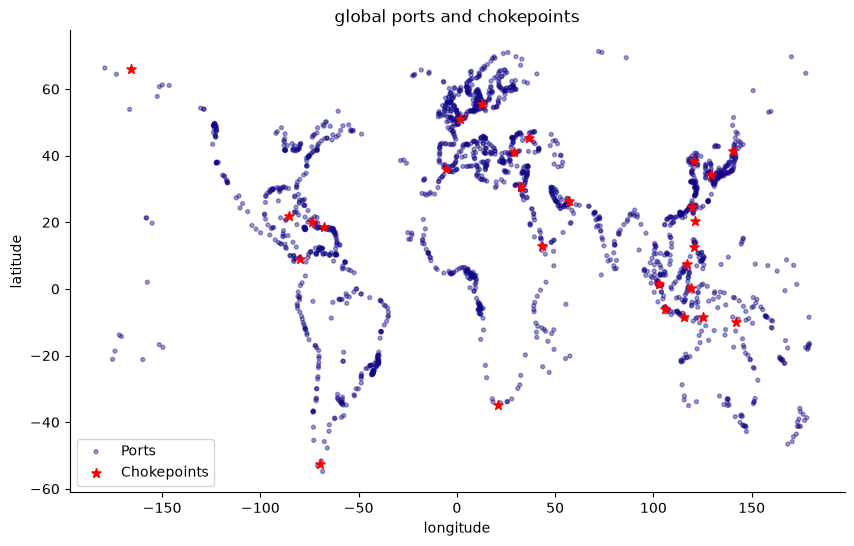

In [44]:
import matplotlib.pyplot as plt 

chokepoints = pd.read_csv("data/PortWatch_chokepoints_database.csv")

plt.figure(figsize=(10, 6))
plt.scatter(x=ports["lon"], y=ports["lat"], c=ports["vessel_count_tanker"], cmap='plasma', alpha=0.4, s=8, label="Ports")
plt.title("global ports and chokepoints")
plt.xlabel("longitude")
plt.ylabel("latitude")

plt.scatter(
    chokepoints["lon"], 
    chokepoints["lat"],
    c="red",
    marker="*",
    s=50,
    label="Chokepoints"
)
plt.legend()

plt.show()


## Disruption Events 

PortWatch uses the Global Disaster Alert and Coordination System for information on natural disasters, and includes information on political tensions as well. The Disruption Events Database has 132 historical weather, geopolitical and other disruption events. 

In [45]:

disruption_events.head()

,eventid,eventtype,eventname,htmlname,htmldescription,alertlevel,country,fromdate,year,todate,...,lat,long,editdate,affectedports,n_affectedports,affectedpopulation,pageid,ObjectId,Shape__Area,Shape__Length
0,1000552,TC,IDAI-19,Tropical Cyclone IDAI-19,"Red Tropical Cyclone IDAI-19 in Mozambique, Zi...",RED,Mozambique,3/9/2019 6:00:00 AM,2019,3/15/2019 12:00:00 AM,...,-19.6000,34.800,9/10/2023 1:47:19 AM,port137,1,1.9 million in Category 1 or higher,3aa1164d42fb42e99f8ed581b6ecd4d1,1,3.500007e+11,3.223230e+06
1,1000227,FL,Flood in Mozambique,Flood in Mozambique,Red Flood in Mozambique from: 09 Mar 2019 00 t...,RED,Mozambique,3/9/2019 12:00:00 AM,2019,3/29/2019 12:00:00 AM,...,-15.1780,36.432,9/10/2023 1:49:27 AM,port137; port784; port896,3,NaN,c2ad419a75d24ec28ae55a0728a0eb79,2,6.425900e+11,5.359811e+06
2,1000559,TC,KENNETH-19,Tropical Cyclone KENNETH-19,"Red Tropical Cyclone KENNETH-19 in , Mozambiqu...",RED,Mozambique; Comoros,4/23/2019 12:00:00 AM,2019,4/25/2019 6:00:00 PM,...,-12.3000,40.100,9/10/2023 1:53:22 AM,port896; port769,2,260 thousand in Category 1 or higher,74c5908f37dd496caedc335fc2bcf6e1,3,2.263530e+11,2.574508e+06
3,1000561,TC,FANI-19,Tropical Cyclone FANI-19,"Red Tropical Cyclone FANI-19 in , India, Bangl...",RED,India,4/27/2019 12:00:00 AM,2019,5/3/2019 12:00:00 PM,...,21.3000,86.200,9/10/2023 1:54:47 AM,port290; port883,2,1.8 million in Category 1 or higher,7a4e3ee5892f497a996870d3e0e6f414,4,5.600202e+11,4.851356e+06
4,1178759,EQ,"Earthquake in Eastern New Guinea Reg., P.N.G.","Earthquake in Eastern New Guinea Reg., P.N.G.",Red M 7.2 Earthquake in Eastern New Guinea Reg...,RED,Papua New Guinea,5/6/2019 9:19:35 PM,2019,5/6/2019 9:19:35 PM,...,-6.9767,146.440,9/10/2023 1:55:14 AM,port624,1,NaN,98299d6738574f2ea18e46e19f71327e,5,3.206445e+10,6.348622e+05



## Duplicate Observations, Completeness, Missingness

### Number of Unique Observations

For $N$ rows in the dataset, $K_{\text{unique}} \in \mathcal{C}$ unique chokepoints and $M_{\text{unique}} \in \mathcal{T}$ unique dates a complete panel should have

$$ 
N = K_{\text{unique}} \cdot M_{\text{unique}}
$$ 

Which we can verify by checking each chokepoint-day $(c, t)$ for uniqueness. And we verify no gaps in the data by checking that $\mathcal{t}_{\text{max}} - \mathcal{t}_{\text{min}} + 1$ is equal to the number of (unique) dates in $\mathcal{T}$. 

- $\forall (c, \, t) \in \mathbb{D}: (c, \, t) \text{ is unique.}$
- $|\mathcal{T}| = t_{\text{max}} - t_{min} + 1$

So in terms of our original description of the data, the panel is complete if 

$$
\Omega = \mathcal{C} \times \mathcal{T} 
$$
$$
N = |\mathcal{C}| \cdot |\mathcal{T}|
$$
$$
N = 28 \times 2848 = \boxed{79,744} \text{ observations}
$$

No duplicates means $\Omega \subseteq \mathcal{C} \times \mathcal{T}$ has exactly $N$ distinct pairs. So if $N = |\mathcal{C}||\mathcal{T}$ that requires that $\Omega = \mathcal{C} \times \mathcal{T}$.   
### Missingness 

Let $M_j$ be the number of missing entries for feature $j$, then the ratio of missing entries for feature $j$ is

$$ r_j = \frac{M_j}{N} $$


In [46]:

daily_chkpnt["date"] = pd.to_datetime(
    daily_chkpnt["date"], errors="coerce"
)

print("daily data shape: ", daily_chkpnt.shape)
print("date range: ", daily_chkpnt["date"].min(), daily_chkpnt["date"].max())

print("Unique chokepoints: ", daily_chkpnt["portid"].nunique())
print("Unique dates: ", daily_chkpnt["date"].nunique())

print("Duplicate chokepoint-date rows: ", daily_chkpnt.duplicated(["portid", "date"]).sum())
print("\nChokepoint Names: ")
print(daily_chkpnt[["portid", "portname"]]
      .drop_duplicates()
      .sort_values("portname")
      .to_string(index=False)
)

print("\nMissing values: ")
print(daily_chkpnt.isna().sum().sort_values(ascending=False).head(15))

daily data shape:  (79744, 21)
date range:  2019-01-01 00:00:00 2026-10-18 00:00:00
Unique chokepoints:  28
Unique dates:  2848
Duplicate chokepoint-date rows:  0

Chokepoint Names: 
      portid             portname
 chokepoint4 Bab el-Mandeb Strait
chokepoint25       Balabac Strait
chokepoint26        Bering Strait
chokepoint17         Bohai Strait
 chokepoint3      Bosporus Strait
 chokepoint7    Cape of Good Hope
 chokepoint9         Dover Strait
 chokepoint8     Gibraltar Strait
chokepoint28         Kerch Strait
chokepoint12         Korea Strait
chokepoint15        Lombok Strait
chokepoint14         Luzon Strait
chokepoint21      Magellan Strait
chokepoint20      Makassar Strait
 chokepoint5       Malacca Strait
chokepoint27       Mindoro Strait
chokepoint24         Mona Passage
chokepoint16         Ombai Strait
chokepoint10       Oresund Strait
 chokepoint2         Panama Canal
 chokepoint6     Strait of Hormuz
 chokepoint1           Suez Canal
chokepoint19         Sunda Strait
c


## Temporal Completeness 

Modeling time series involves using a 1 day lag and a $k$ day rolling window to prevent data leakage. This requires that the samples from the time series are complete and chronological. 

A mean taken from a 7-day window is only valid if days are sequential and each day in the time period is represented. 

In [47]:

expected_days = (
    daily_chkpnt["date"].max() - daily_chkpnt["date"].min()
).days + 1


coverage = daily_chkpnt.groupby("portname").agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    days_observed=("date", "nunique")
)

print("Expected days: ", expected_days)
print("Expected rows: ", expected_days * daily_chkpnt["portid"].nunique())
print("All dates covered" if coverage[coverage["days_observed"] != expected_days].empty else f"missing {len(coverage[coverage["days_observed"] != expected_days])} days")

Expected days:  2848
Expected rows:  79744
All dates covered



## Descriptive Analysis 


We calculate the mea, standard deviation, variance, median, maximum and minimum of n_total ships for time period $T \subseteq \mathcal{T}$. First for all chokepoints, then for each.

The per chokepoint statistics are defined
### Mean daily traffic $\bar{x}$

$$
\bar{x}_c = \frac{1}{|T|} \sum_{t \in T} x_{c, t}
$$

### Sample variance and standard deviation $\sigma^2, \, \sigma$

$$
\sigma_c^2 = \frac{1}{|T| - 1} \sum_{t \in T} (x_{c, t} - \bar{x}_c)^2
$$

$$
\sigma_c = \sqrt{\sigma_c^2}
$$

### Median $\widetilde{x}$ 

$$
\widetilde{x}_c = \operatorname{median}\{x_{c,t} : t \in T\}
$$ 

These calculations are run first for the entire time series ($T = \mathcal{T}$), and later for specific windows. 


In [48]:

print("Aggregate statistics across all chokepoints: ")
print(daily_chkpnt[["n_total", "n_cargo", "capacity"]].describe())

traffic_summary = daily_chkpnt.groupby("portname").agg(
    mean_traffic=("n_total", "mean"),
    median_traffic=("n_total", "median"),
    std_traffic=("n_total", "std"),
    min_traffic=("n_total", "min"),
    max_traffic=("n_total", "max")
).sort_values("mean_traffic", ascending=False)

print("\nStatistics per Chokepoint")
print(traffic_summary.to_string())

Aggregate statistics across all chokepoints: 
            n_total       n_cargo      capacity
count  79744.000000  79744.000000  7.974400e+04
mean      70.714850     49.875389  2.107666e+06
std       71.157017     51.801458  2.102331e+06
min        0.000000      0.000000  0.000000e+00
25%       17.000000     12.000000  2.920890e+05
50%       46.000000     32.000000  1.410168e+06
75%       95.000000     66.000000  3.257265e+06
max      472.000000    352.000000  1.632013e+07

Statistics per Chokepoint
                      mean_traffic  median_traffic  std_traffic  min_traffic  max_traffic
portname                                                                                 
Taiwan Strait           243.332865           245.0    37.252838            7          472
Korea Strait            227.948385           230.0    32.217819            1          448
Malacca Strait          199.633076           206.0    33.867433          101          298
Bohai Strait            175.634129           


## Visualizing raw time series 

In theory, the underlying function of chokepoint traffic could be defined by the combined effects of traffic trends, seasonal patterns, disruptoin events and noise. 

- Trend $\tau$: whether typical traffic changes over an observation period. 
- Seasonality $s$: recurring calendar patterns. 
- Disruption events $\delta$: weather, geopolitical, and other chokepoint disruption events.
- Unknown factors and variation $\varepsilon$: Affects from unquantified sources, and whether individual observations fluctuate substantially due to noise. 

$\large{\textbf{Chokepoint Traffic} = \tau_{c,t} + s_{c, t} + \delta_{c,t} + \varepsilon_{c, t}}$

The problem for this experiment is that it is likely for a large proportion of the future traffic to be dependent on factors for which we do not have data ($\varepsilon$). 

We can plot data for a selection of ports to see how noisy the data appears. 

#### Traffic Over Time at Select Checkpoints

Each chokepoint is its own time series, with its own average traffic, trends and seasonal patterns.

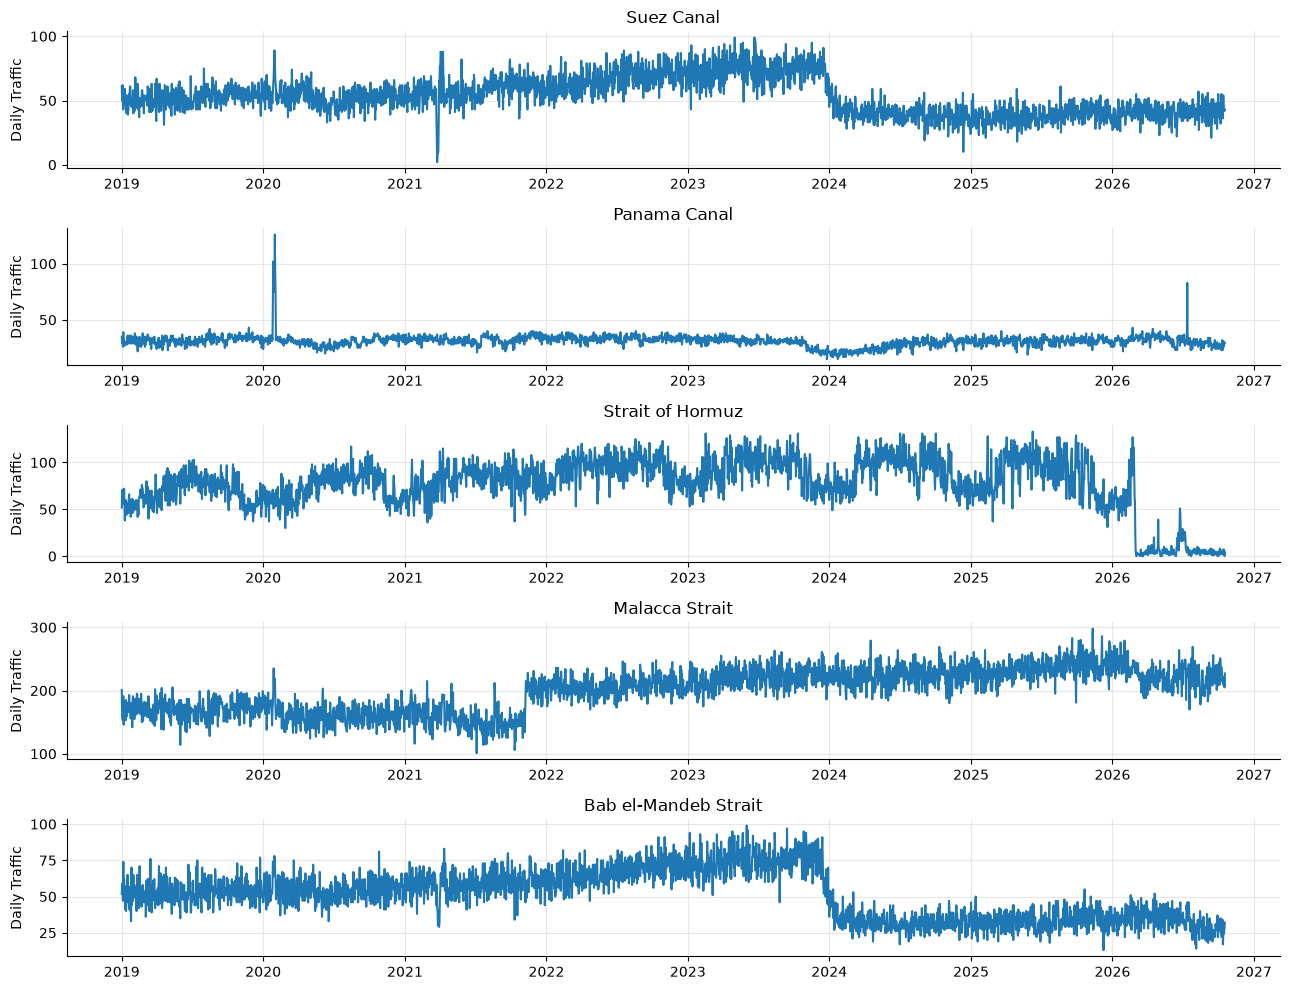

In [49]:

test_ports = [
    "Suez Canal",
    "Panama Canal",
    "Strait of Hormuz",
    "Malacca Strait",
    "Bab el-Mandeb Strait"
]

fig, axes = plt.subplots(len(test_ports), 1, figsize=(13, 10))

for ax, name in zip(axes, test_ports):
    subset = daily_chkpnt[daily_chkpnt["portname"] == name].sort_values("date")

    ax.plot(subset["date"], subset["n_total"])
    ax.set_title(name)
    ax.set_ylabel("Daily Traffic")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Checking Availability and Validity of Disruption Labels

For successful classification, the model needs to be trained on sufficient valid labeled events. A disruption $\xi$ can be linked to our panel if it names a chokepoint, and we can count for each chokepoint the number of events that affect it. 

For the set of all disruptions $\Xi$, and the set of affected locations $A$, and the interval of time associated with the disruption $[a_\xi, b_\xi]$:
$$
\Xi_{\text{valid}} = \{\, \xi \in \Xi : A_\xi \cap \mathcal{C} \neq \emptyset \, \}
$$

We can then define a disruption event $E$ for chokepoint-day $(c, t)$ as 

$$
E_{c, t} = 
\begin{cases}
1 & \text{if } \exists\, \xi \in \Xi_{\text{valid}} : c \in A_\xi \text{ and } t \in [a_\xi, b_\xi] \\
0 & \text{otherwise}
\end{cases}
$$



We map disruption events from ```data/pw_disruptions_db.csv``` to chokepoints and count how may qualifying events exist in the data. 

In [50]:

for col in ["fromdate", "todate"]:
    disruption_events[col] = pd.to_datetime(disruption_events[col], errors="coerce")

print("Disruption event records:", len(disruption_events))
print("Disruption types: ")
print(disruption_events["eventtype"].value_counts(dropna=False))

print("\nAlert levels: ")
print(disruption_events["alertlevel"].value_counts(dropna=False))

print("\nDisruption event date range: ")
print("Earliest start: ", disruption_events["fromdate"].min())
print("Latest start: ", disruption_events["fromdate"].max())

print("\nMissing dates: ")
print(disruption_events[["fromdate", "todate"]].isna().sum())

print("\nSample event records: ")
print(
    disruption_events[
        ["eventid", "eventtype", "eventname", "fromdate", "todate", "severitytext", "affectedports", "n_affectedports"]
    ].head(10).to_string(index=False)
)

Disruption event records: 132
Disruption types: 
eventtype
TC    72
EQ    32
FL    14
OT     5
DR     4
WF     3
VO     2
Name: count, dtype: int64

Alert levels: 
alertlevel
RED       131
ORANGE      1
Name: count, dtype: int64

Disruption event date range: 
Earliest start:  2018-10-21 00:00:00
Latest start:  2026-08-14 21:58:21

Missing dates: 
fromdate    0
todate      2
dtype: int64

Sample event records: 
 eventid eventtype                                     eventname            fromdate              todate                                                severitytext                                                                                                                                                             affectedports  n_affectedports
 1000552        TC                                       IDAI-19 2019-03-09 06:00:00 2019-03-15 00:00:00 Hurricane/Typhoon > 74 mph (maximum wind speed of 194 km/h)                                                                      

/tmp/ipykernel_2142/3385859938.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  disruption_events[col] = pd.to_datetime(disruption_events[col], errors="coerce")


In [51]:

chokepoint_reference = pd.read_csv("data/PortWatch_chokepoints_database.csv")

disruption_event_port_ids = set(
    disruption_events["affectedports"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

daily_ids = set(daily_chkpnt["portid"].dropna().astype(str))
reference_ids = set(chokepoint_reference["portid"].dropna().astype(str))

print("\nSample event port IDs: ", sorted(disruption_event_port_ids)[:15])
print("Sample daily IDs: ", sorted(daily_ids)[:15])
print("Sample reference IDs: ", sorted(reference_ids)[:15])

print("\nDisruption event IDs matching daily IDs: ", len(disruption_event_port_ids & daily_ids))
print("Event IDs matching reference IDs: ", len(disruption_event_port_ids & reference_ids))
print("Daily IDs matching reference IDs: ", len(daily_ids & reference_ids))

print("\nReference table IDs and names: ")
print(chokepoint_reference[["portid", "portname"]].head(35).to_string(index=False))


Sample event port IDs:  ['chokepoint1', 'chokepoint2', 'chokepoint4', 'chokepoint6', 'chokepoint7', 'port1023', 'port1025', 'port1028', 'port1029', 'port103', 'port1030', 'port1055', 'port1056', 'port1065', 'port1067']
Sample daily IDs:  ['chokepoint1', 'chokepoint10', 'chokepoint11', 'chokepoint12', 'chokepoint13', 'chokepoint14', 'chokepoint15', 'chokepoint16', 'chokepoint17', 'chokepoint18', 'chokepoint19', 'chokepoint2', 'chokepoint20', 'chokepoint21', 'chokepoint22']
Sample reference IDs:  ['chokepoint1', 'chokepoint10', 'chokepoint11', 'chokepoint12', 'chokepoint13', 'chokepoint14', 'chokepoint15', 'chokepoint16', 'chokepoint17', 'chokepoint18', 'chokepoint19', 'chokepoint2', 'chokepoint20', 'chokepoint21', 'chokepoint22']

Disruption event IDs matching daily IDs:  5
Event IDs matching reference IDs:  5
Daily IDs matching reference IDs:  28

Reference table IDs and names: 
      portid             portname
 chokepoint1           Suez Canal
 chokepoint2         Panama Canal
 chok

In [52]:
chokepoint_ids = set(daily_chkpnt["portid"].unique())

# 1. Split the semicolon-separated 'affectedports' string into a list of IDs
disruption_events["affected_id_list"] = (
    disruption_events["affectedports"]
    .fillna("")
    .apply(lambda x: [i.strip() for i in x.split(";") if i.strip()])
)

# 2. Classify each event based on whether it directly references a chokepoint ID
def classify_mapping(ids):
    if not ids:
        return "No affected ports listed"
    if any(p in chokepoint_ids for p in ids):
        return "Direct chokepoint reference"
    return "Port-only reference"

disruption_events["mapping_type"] = disruption_events["affected_id_list"].apply(classify_mapping)

In [53]:


chokepoint_ids = set(daily_chkpnt["portid"].unique())
direct = disruption_events[
    disruption_events["mapping_type"] == "Direct chokepoint reference"
].copy()

direct["matched_chokepoints"] = direct["affected_id_list"].apply(
    lambda ids: [
        p for p in ids if p in chokepoint_ids
    ]
)
print(pd.crosstab(disruption_events["eventtype"], disruption_events["mapping_type"], margins=True))

print("\nChokepoints with any direct event: ", 
      direct["matched_chokepoints"].explode().nunique(), "of", len(chokepoint_ids))

print(direct[["eventname", "fromdate", "todate", "matched_chokepoints"]].to_string(index=False))

mapping_type  Direct chokepoint reference  No affected ports listed  \
eventtype                                                             
DR                                      0                         2   
EQ                                      0                        22   
FL                                      0                         6   
OT                                      3                         0   
TC                                      0                        10   
VO                                      0                         1   
WF                                      0                         3   
All                                     3                        44   

mapping_type  Port-only reference  All  
eventtype                               
DR                              2    4  
EQ                             10   32  
FL                              8   14  
OT                              2    5  
TC                             62   72  
VO

## Why the labeled disruptions are not useable. 

The disruptions database covers weather, geopolitical, commercial disruptions across all global ports, not just those that affect chokepoints. 

Of the 132 recorded events in ```pw_dusruptions_db.csv```, 131 are so-called RED alerts, but many of those are one of the 104 weather events such as hurricanes or earthquakes. Only 3 disruption records reference a chokepoint directly, and those 3 events affect a combined total of 5 chokepoints out of 28 (Suez, Bab al-Mandeb, Cape of Good Hope, Panama, and Hormuz). 85 name only ordinary ports, and 44 name no location at all. 

Of the 5 disruptions that affect chokepoints, only 3 have an end date (disruptions are potentially ongoing), so there would only be 2 events for training and 1 for testing which provides virtually nothing for a model to learn. 

We therefore cannot predict disruptions, and instead define a **traffic slowdown** as forecasted drop below some percentage of the recent traffic baseline. 

# Modeling Maritime Traffic Slowdowns
Using the total number of ships passing through chokepoints, we can instead model traffic slowdown defined by a significant drop in the ships traversing a chokepoint in a certain time window. We use the Daily Chokepoints Database, grouped by portid and n_total ships traversing. 

## Feature engineering 

For chokepoint $c$ and date $t$, every feature is calculated from the previous 28 days in two historical periods. 

1. A 28 day historical period from $t-28$ days to $t-1$ days for calculating baseline metrics. 
2. A 7 day recent period from $t-7$ to $t-1$ for calculating recent traffic average. 

| Feature | Definition | Captures |
|---|---|---|
| Lag | $L_{c, t} = x_{c, t-1}$ | yesterday's traffic |
| 7-day mean | $\mu^{(7)}_{c, t} = \frac{1}{7}\sum_{k=1}^{7} x_{c, t-k}$ | recent traffic level |
| 28-day mean | $\mu^{(28)}_{c, t} = \frac{1}{28} \sum_{k=1}^{28} x_{c, t-k}$ | baseline traffic rate |
| 28-day std | $\sigma^{(28)}_{c, t} = \sqrt{\frac{1}{27}\sum_{k=1}^{28}\big(x_{c, t-k}-\mu^{(28)}_{c, t}\big)^2}$ | variability |

Because the label is relative to the baseline, we also calculate ratios compared to the baseline, do represent the proportional shifts in traffic in a way that can be compared across all chokepoints. 

$$
r^{(7/28)}_{c, t} = \frac{\mu^{(7)}_{c, t}}{\mu^{(28)}_{c, t}}, \qquad
r^{L}_{c, t} = \frac{L_{c ,t}}{\mu^{(28)}_{c, t}}, \qquad
\mathrm{cv}_{c, t} = \frac{\sigma^{(28)}_{c, t}}{\mu^{(28)}_{c, t}}
$$

Chokepoint identity is encoded as a one-hot vector $\mathbf{e}_c \in \{0, 1\}^{28}$, where the $c$-th element of the vector is 1 with all others 0 to identify the chokepoint. This is done so the model does not learn a linear relationship between the categorical chokepoint id numbers and the target. 

The feature vector $\mathbf{z}_{c, t}$ contains these features for each chokepoint-day $(c, t)$ in the dataset. 

The initial tests use only $L, \mu^{(7)}, \mu^{(28)}, \sigma^{(28)}$ and $\mathbf{e}_c$. After analyzing those results, the ratio features were added and the model was run again. Ablation was performed on the full feature set to identify the primary drivers of any predictive power. 

## Target 

We use the features calculated from previous 7 and 28 day periods from day $t$ to predict the average traffic over the following 7 days, and we compare this prediction agains the ground truth 7 day average for the forecast period, which we will call $F$.

$$
F_{c,t} = \frac{1}{7} \sum_{k=1}^{7} x_{c,t+k}
$$

For a threshold $\theta = 0.7$, the slowdown label is defined

$$
y_{c, t} = \mathbb{I}\!\left[\, F_{c, t} < \theta, \,\,\, \mu^{(28)}_{c, t} \, \right]
$$

The model never predicts $F$, it only estimates $P(y_{c, t} = 1 \mid \mathbf{z}_{c, t})$ directly.  

## Complete Dataset 

A row $(c, t)$ is usable only if there are 28 days before it and 7 days after it and $\mu^{(28)}_{c, t} > 0$. We therefore define $\Omega^* \subseteq \Omega$ be the valid, usable set, with $n = |\Omega^*| = 78{,}244$ rows. Combining all usable chokepoint-days into a matrix we get

$$
\mathbb{D}_{\text{model}} = \{(\mathbf{z}_{c, t}, \,\, y_{c, t}) : (c, t) \in \Omega^*\}, \qquad \mathbb{X} \in \mathbb{R}^{n \times p}, \quad \mathbf{y} \in \{0, 1\}^n
$$

where row $(c, t)$ of $\mathbb{X}$ is $\mathbf{z}_{c, t}^\top$. The result is a single pooled dataset with chokepoint identity encoded in the one-hot vector $\mathbf{e}_c$

The complete dataset now resembles a standard classification dataset with features $\mathbb{X}$ and targets $\mathbf{y}$. Importantly, there is essentially one  complete timeseries per chokepoint, and therefore one subset of the data for each, pooled to yield more positives per fit.  

## Timing and leakage 

Features are calculated from dates in $t-28, \dots, t-1$. The label uses days $t+1, \dots, t+7$, and day $t$ is excluded from both. This is how we ensure that the windows never overlap. 

Rows at adjacent dates have highly correlated targets, because they share 6 of 7 target dates. To prevent data contamination between train and test splits, a 7-day gap buffer is included between train and test sets. 

For bootstrap resamples, the timeseries was made circular and blocks of contiguous dates were sampled, not individual rows.  

In other words for each of 28 Chokepoints, we record metrics for every day $t \in T$ in the time series starting from day 28 using a Moving Average Window of 28 days, 7 days, and 1 day. For each recorded window looking backwards, we record the corresponding 7 day forecast of the average traffic for the following 7 days, which is the target. This ensures that for a given prediction, no data from after the day $t$ on which the prediction is based is included in the feature vector $X$ which will be used to predict the target $\textbf{y}$.   

In [54]:

df = daily_chkpnt.sort_values(["portid", "date"]).copy()

g = df.groupby("portid")["n_total"]

#features for traffic model, *historical* traffic only 
df["lag1"] = g.shift(1)
df["mean_7day"] = g.transform(
    lambda s: s.shift(1).rolling(7).mean()
)

df["mean_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).mean()
)
df["std_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).std()
)

#this will be target, average traffic over the following seven days
df["future_mean_7day"] = g.transform(
    lambda s: s.rolling(7).mean().shift(-7)
)

#mask cases where the mean is <= 0
valid_baseline = df["mean_28day"] > 0

df["slowdown"] = pd.NA
df.loc[valid_baseline, "slowdown"] = (
    df.loc[valid_baseline, "future_mean_7day"] < 0.70 * df.loc[valid_baseline, "mean_28day"]
).astype(int)

features = ["lag1", "mean_7day", "mean_28day", "std_28day"]

model_data = df.dropna(
    subset=features + ["future_mean_7day", "slowdown"]
).copy()

model_data["slowdown"] = model_data["slowdown"].astype(int)

print("Usable observations: ", len(model_data))
print("\nTarget distribution: ")
print(model_data["slowdown"].value_counts())
print("\nTarget proportions: ")
print(model_data["slowdown"].value_counts(normalize=True))

Usable observations:  78244

Target distribution: 
slowdown
0    75975
1     2269
Name: count, dtype: int64

Target proportions: 
slowdown
0    0.971001
1    0.028999
Name: proportion, dtype: float64


## Testing Different Thresholds, Forecasts, Baselines

The 28 day window for baseline calculation, 7 day forecast window, and $\theta = 0.7$ threshold for a positive hit (traffic below 70\% of 28 day average) yieled $2269 / 78244$ or $2.9\%$ total usable observations. Here I tested how different baseline windows, forecast horizons, and thresholds affect that ratio. 

After this analysis, I determined that any threshold less than 70\% is hard to justify as a significant slowdown, and any threshold greater only yields less positives, so I stuck with the original choices. 

In [55]:
# Testing different baseline calculation windows, forecast windows, and thresholds for a slowdown

df2 = daily_chkpnt.sort_values(["portid", "date"]).copy()

g = df2.groupby("portid")["n_total"]

baseline_windows = [2, 8, 14, 28, 56]
forecast_horizons = [1, 4, 7, 14, 28]

thresholds = [0.50, 0.60, 0.70, 0.80]
results = []

for b_days in baseline_windows:
    baseline = g.transform(
        lambda s: s.shift(1).rolling(b_days).mean()
    )

    for horizon in forecast_horizons:
        future_mean = g.transform(
            lambda s: s.rolling(horizon).mean().shift(-horizon)
        )

        valid = baseline.gt(0) & future_mean.notna()

        for threshold in thresholds:
            slowdown = (
                future_mean[valid] < threshold * baseline[valid]
            )

            results.append({
                "baseline_days": b_days, 
                "forecast_days": horizon,
                "threshold": threshold,
                "usable_rows": int(valid.sum()),
                "positive_counts": int(slowdown.sum()),
                "positive_rate": slowdown.mean()
            })

results_df = pd.DataFrame(results)

print(
    results_df.sort_values(
        ["forecast_days", "baseline_days", "threshold"]
    ).to_string(index=False)
)

 baseline_days  forecast_days  threshold  usable_rows  positive_counts  positive_rate
             2              1        0.5        78007             2612       0.033484
             2              1        0.6        78007             4324       0.055431
             2              1        0.7        78007             7433       0.095286
             2              1        0.8        78007            12983       0.166434
             8              1        0.5        78440             3003       0.038284
             8              1        0.6        78440             4482       0.057139
             8              1        0.7        78440             7163       0.091318
             8              1        0.8        78440            12121       0.154526
            14              1        0.5        78524             3213       0.040917
            14              1        0.6        78524             4706       0.059931
            14              1        0.7        78524 

# Model Design 

## Train-Test Splits

Time series data has a meaningful chronological order, and therefore cannot be shuffled and split like ordinary classification datasets. Instead of shuffling, the first model was trained and tested by splitting at a single date $T_0$, with all training data taken from before that date and all test data from after. A 7-day gap is included between train and test sets to ensure that there is no overlap. 


### Walk-forward split


Subsequent models were trained and tested with $K=9$ "walk forward" folds. 

Fold $k$ has a six month test window $[T_0^{(k)}, T_1^{(k)}]$, witn windows starting every 6 months from January 1st, 2022. 

Since $y_{c, t}$ depends on $x{c, t+1} \dots $x{c, t+7}$, only those training rows whose target window ends before the test period begins are allowed in the training data. We use a 7-day gap $H$ between train and test sets. 
$$
\Omega^{\text{train}}_k = \{(c, t) \in \Omega^* : t + H < T_0^{(k)}\}, \qquad 
\Omega^{\text{test}}_k = \{(c, t) \in |Omega^* : T_0^{(k)} \le t < T_1^{(k)}\}
$$

Without this gap, the last training labels would be calculated from traffic in the test period. Test-row features can however use days before $T_0^{(k)}$ since anything in the past is valid for future predictions. 

The model is refit for each fold, and the predictions from each fold are pooled for final evaluation. 

## Pipeline 

**Standardization** Using the Standard Scaler from Sci-Kit Learn, scaling computes the training mean $\bar{z}_j$ and standard deviation $s_j$, applied to both training and test rows. 

$$
z_j^* = \frac{z_j - \bar{z}_j}{s_j}
$$

All statistics are calculated from training rows only, so no test information is included in scaling. 

**Logistic Regression** 

With standardized features $\mathbf{z}^*$, the model computes a linear score from the features, converted to a probability with sigmoid, and used to predict the label $y$ of traffic in the forecasted period. 

$$
\eta = \beta_0 + \sum_{j=1}^{p} \beta_j z_j^*, \qquad
P(y = 1 \mid \mathbf{z}) = \sigma(\eta) = \frac{1}{1 + e^{-\eta}}
$$

In the sklearn default configuration, coefficients $\beta$ are calculated to mininmize the log-loss, plus an L2 penalty (sklearn). 

$$
\min_{\beta}\ \tfrac{1}{2}\lVert \beta \rVert^2 + C \sum_{i} w_{y_i}\, \ell\big(y_i, \hat{p}_i\big), \qquad w_y = \frac{n}{2\, n_y}
$$

For log loss $\ell$ and number of training rows $n_y$ in class $y$. Model was set to "class_weights='balanced'", which skews the results such that the predicted probabilities are no longer consistent with true frequencies and we can no longer test against a 0.5 baseline cutoff. Instead we evaluate the ranking of the scores rather than a fixed threshold. 

Scaler and Classifier are both used in one pipeline. Fit on $\Omega^{\text{train}}_k$ and scored on the test set $\Omega^{\text{test}}_k$. 

## Metric and baselines 

Because slowdowns are so rare in the data ($\approx 3\%$ of rows), accuracy is not an informative metric for evaluation. A model that always predicts 0 (no slowdown) would achieve $\approx 97\%$ accuracy, so a better metric for this data is **Average Precision**. 

$$
\mathrm{AP} = \sum_m (R_m - R_{m-1})\, P_m
$$

This represents the area under the precision-recall curve for precision $P_m$ and recall $R_m$ of the m-th score cutoff. A dummy model with no information will achieve an AP score equal to the share of positive rows $\pi$. 

Results compared against: 

- **Prior Classifier** scores every row the same, AP = $\pi$. This serves only as evidence that the model performs better than random chance. 
$$
\mathrm{Score}_{c, t} = P(\hat{y} = y) \cdot n
$$

- **Persistence Rule** is a more meaningful baseline, which scores each row by how far recent traffic is below the baseline. 

$$
\mathrm{Score}_{c, t} = 1 - r^{(7/28)}_{c, t}
$$

Additionaly, **macro-AP** was calculated as the mean of AP within each chokepoint if that chokepoint has positives above a reasonable cutoff. This is useful because the pooled mtric weights chokepoints by number of positives, resulting in a few low-traffic series dominating  the calculation. 

**Uncertainty** is estimated as part of the block bootstrap process. 



In [56]:

#first attempt at statistical modeling

import numpy as np 

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, confusion_matrix

df = pd.read_csv(
    "data/Daily_Chokepoints_Data.csv",
    parse_dates=["date"]
)


df = df.sort_values(["portid", "date"]).copy()
g = df.groupby("portid")["n_total"]

df["traffic_lag1"] = g.shift(1)

df["mean_7day"] = g.transform(
    lambda s: s.shift(1).rolling(7).mean()
)

df["mean_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).mean()
)

df["std_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).std()
)

#target: 
df["future_mean_7day"] = g.transform(
    lambda s: s.rolling(7).mean().shift(-7)
)

valid = (
    df["mean_28day"].gt(0) & df["future_mean_7day"].notna()
)

df["slowdown"] = np.nan

df.loc[valid, "slowdown"] = (
    df.loc[valid, "future_mean_7day"] < 0.7 * df.loc[valid, "mean_28day"]
).astype(int)
features = [
    "traffic_lag1",
    "mean_7day",
    "mean_28day",
    "std_28day"
]
model_data = df.dropna(
    subset=features + ["slowdown"]
).copy()

chokepoint_features = pd.get_dummies(
    model_data["portid"].astype(str),
    prefix="cp",
    dtype=int
)

X = pd.concat(
    [model_data[features], chokepoint_features],
    axis=1
)

y = model_data["slowdown"].astype(int)

#split chronologically
cutoff = pd.Timestamp("2025-01-01")

#we purge 7 days before the test period, and keep future traffic from test period out of training
train = model_data["date"] < cutoff - pd.Timedelta(days=7)
test = model_data["date"] >= cutoff

X_train, X_test = X.loc[train], X.loc[test]
y_train, y_test = y.loc[train], y.loc[test]

print("Training Rows: ", len(X_train))
print("Test Rows: ", len(X_test))
print("Test positive rate: ", y_test.mean())

#baseline classification performance:
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)
dummy_probabilities = dummy.predict_proba(X_test)[:, 1]

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    )
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print(
    "Dummy average precision: ",
    average_precision_score(y_test, dummy_probabilities)
)
print(
    "Model average precision: ",
    average_precision_score(y_test, probabilities)
)
print("Precision: ", precision_score(y_test, predictions, zero_division=0))
print("Recall: ", recall_score(y_test, predictions, zero_division=0))
print("Confusion matrix: ")
print(confusion_matrix(y_test, predictions))

Training Rows:  59892
Test Rows:  18156
Test positive rate:  0.035966071821987224
Dummy average precision:  0.035966071821987224
Model average precision:  0.3813784758383886
Precision:  0.22739018087855298
Recall:  0.8085758039816233
Confusion matrix: 
[[15709  1794]
 [  125   528]]



# Initial Results 

On approximatiely 59k rows of training data and 18k rows held out for testing, the results are as follows: 

Rate of Positive Targets: $\approx 3.6\%$

Average Precision of Dummy Classifier using Prior Probabilities: $\approx 3.6\%$

Model Average Precision: $\approx 38\%$

Model Precision: $\approx 22.7\%$

Model Recall: $\approx 81\%$

### Confusion Matrix: 
$$
\begin{array}{c|cc}
 & \text{Predict No Slowdown} & \text{Predict Slowdown} \\
 \hline
 \text{No Slowdown} & 15709 & 1794 \\
 \text{Slowdown} & 125 & 528 
 \end{array}
 $$


From the initial test at threshold 0.7, the model performed about 10X better than the dummy classifier baseline, suggesting that the model is infact learning something valuable in the training data. This is not particularly surprising, the real question is whether the definition of significant traffic slowdown is meaningful, whether the prediction in any real world setting, and whether the model could be used to predict on an entirley separate time window with any degree of reliability. 


# Exploratory Analysis on Classifier

Testing different thresholds, measuring performance tradeoffs. 

The remainder of this analysis is an exploration of how different thresholds influence model performance, with the goal of fine tuning the threshold to achieve the best performance while maintaing a defensible threshold for alerts of traffic slowdowns.





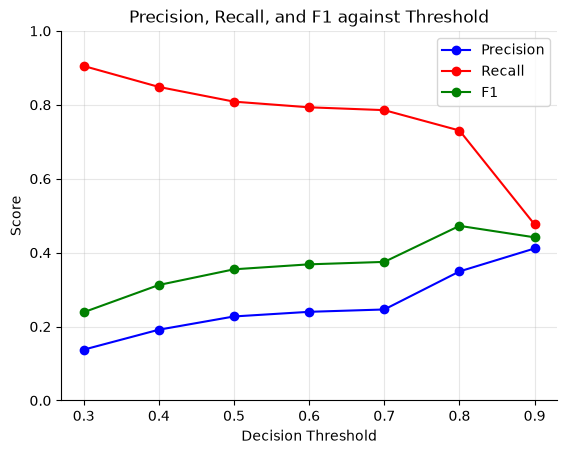

In [57]:

#attempting different thresholds
from sklearn.metrics import f1_score
stats_by_threshold = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    cur_preds = (probabilities >= threshold).astype(int)
    cur_precision = precision_score(y_test, cur_preds, zero_division=0)
    cur_recall = recall_score(y_test, cur_preds, zero_division=0)
    cur_f1 = f1_score(y_test, cur_preds, zero_division=0)

    stats = {
        "threshold": threshold,
        "alerts": cur_preds.sum(),
        "predictions": cur_preds,
        "precision": cur_precision,
        "recall": cur_recall,
        "f1": cur_f1
    }
    stats_by_threshold.append(stats)

stats_df = pd.DataFrame(stats_by_threshold)
plt.figure()
plt.plot(
    stats_df["threshold"], stats_df["precision"], marker="o", color="blue", label="Precision"
)
plt.plot(
    stats_df["threshold"], stats_df["recall"], marker="o", color="red", label="Recall" 
)
plt.plot(
    stats_df["threshold"], stats_df["f1"], marker="o", color="green", label="F1"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1 against Threshold")
plt.xticks(stats_df["threshold"])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


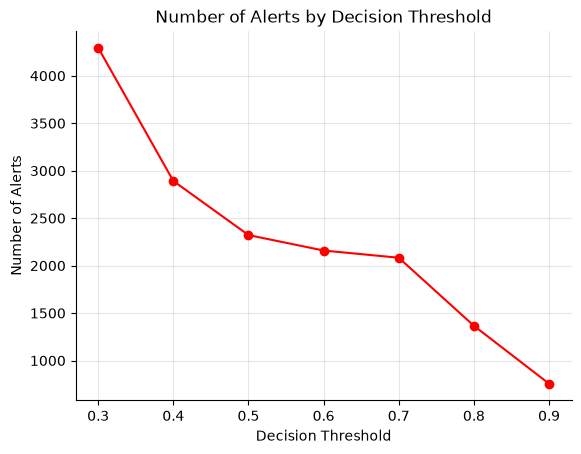

In [58]:

#plotting alerts to track relationship with changes in threshold

plt.figure()
plt.plot(
    stats_df["threshold"], stats_df["alerts"], marker="o", color="red"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Number of Alerts")
plt.title("Number of Alerts by Decision Threshold")
plt.xticks(stats_df["threshold"])
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipykernel_2142/1628965560.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


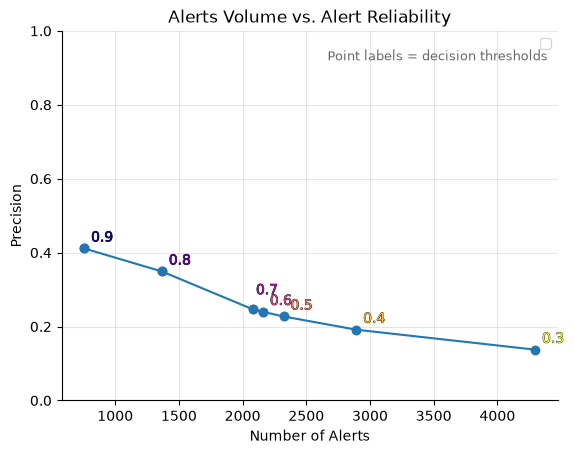

In [59]:

#plotting alerts against precision
import matplotlib.patheffects as pe
plt.figure()
plt.plot(
    stats_df["alerts"], stats_df["precision"], marker="o"
)

colors = plt.cm.plasma_r(np.linspace(0, 1, len(stats_df)))
for (i, row), color in zip(stats_df.iterrows(), colors):
    plt.scatter(row["alerts"], row["precision"], color=color)
    plt.annotate(
        f'{row["threshold"]:.1f}',
        (row["alerts"], row["precision"]),
        xytext=(2, 11) if row["threshold"] == 0.7 else (5, 5),
        textcoords="offset points",
        color=color,
        path_effects=[pe.withStroke(linewidth=0.5, foreground="black")]
    )

plt.xlabel("Number of Alerts")
plt.ylabel("Precision")
plt.title("Alerts Volume vs. Alert Reliability")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.text(0.98, 0.95, "Point labels = decision thresholds", transform=plt.gca().transAxes, ha="right", 
         va="top", fontsize=9, color="dimgray")
plt.legend()

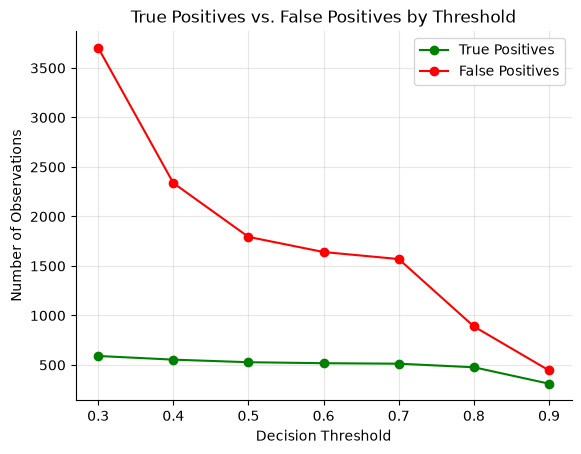

In [60]:

for stats in stats_by_threshold:
    tn, fp, fn, tp = confusion_matrix(y_test, stats["predictions"], labels=[0,1]).ravel()

    stats["true_positives"] = tp
    stats["false_positives"] = fp
    stats["false_negatives"] = fn
    stats["true_negatives"] = tn

stats_df = pd.DataFrame(stats_by_threshold)

plt.figure()
plt.plot(stats_df["threshold"], stats_df["true_positives"], marker="o", color="green", label="True Positives")
plt.plot(stats_df["threshold"], stats_df["false_positives"], marker="o", color="red", label="False Positives")
plt.xlabel("Decision Threshold")
plt.ylabel("Number of Observations")
plt.title("True Positives vs. False Positives by Threshold")
plt.xticks(stats_df["threshold"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# Precision and Recall @ K

Precision@K and Recall@K are evaluation metrics that test the top K precision and recall scores against all positive labels. 

According to \url{https://www.evidentlyai.com/ranking-metrics/precision-recall-at-k}, these metrics are spceifically designed to evaluate quality of recommender systems.

* Precision at K

From the site, "Precision@K is the ratio of correctly identified relevant items within the total recommended items inside the K-long list." Or in other words it is meant to show how many recommended items are genuinely relevant. 

* Recall at K 

Recall@K on the other hand, measures the proportion of the topK recommendations that are correctly identified out of the total number of relevant items (positive labels) in the dataset or subset. This metric is meant to show how many of the positive labels your model was able to successfully identify. 

In [61]:
def precision_recall_at_k(y_true, y_scores, k):
    # indices of the K highest predicted probabilities
    top_k = np.argsort(y_scores)[::-1][:k]

    # actual labels for the K predictions
    top_k_labels = np.asarray(y_true)[top_k]

    precision_K = top_k_labels.sum() / k

    recall_K = top_k_labels.sum() / np.asarray(y_true).sum()

    return precision_K, recall_K

K_precisions = []
K_recalls = []
# Testing at different K values
k_values = [2, 3, 5, 7, 10, 25, 50, 100, 500]
for k in k_values:

    precision_k, recall_k = precision_recall_at_k(
        y_test,
        probabilities,
        k
    )
    K_precisions.append(precision_k)
    K_recalls.append(recall_k)
    print(f"\nK = {k}")
    print(f"Precision@K: {precision_k:.4f}")
    print(f"Recall@K: {recall_k:.4f}")


K = 2
Precision@K: 1.0000
Recall@K: 0.0031

K = 3
Precision@K: 1.0000
Recall@K: 0.0046

K = 5
Precision@K: 1.0000
Recall@K: 0.0077

K = 7
Precision@K: 1.0000
Recall@K: 0.0107

K = 10
Precision@K: 1.0000
Recall@K: 0.0153

K = 25
Precision@K: 0.8400
Recall@K: 0.0322

K = 50
Precision@K: 0.6800
Recall@K: 0.0521

K = 100
Precision@K: 0.5500
Recall@K: 0.0842

K = 500
Precision@K: 0.4540
Recall@K: 0.3476


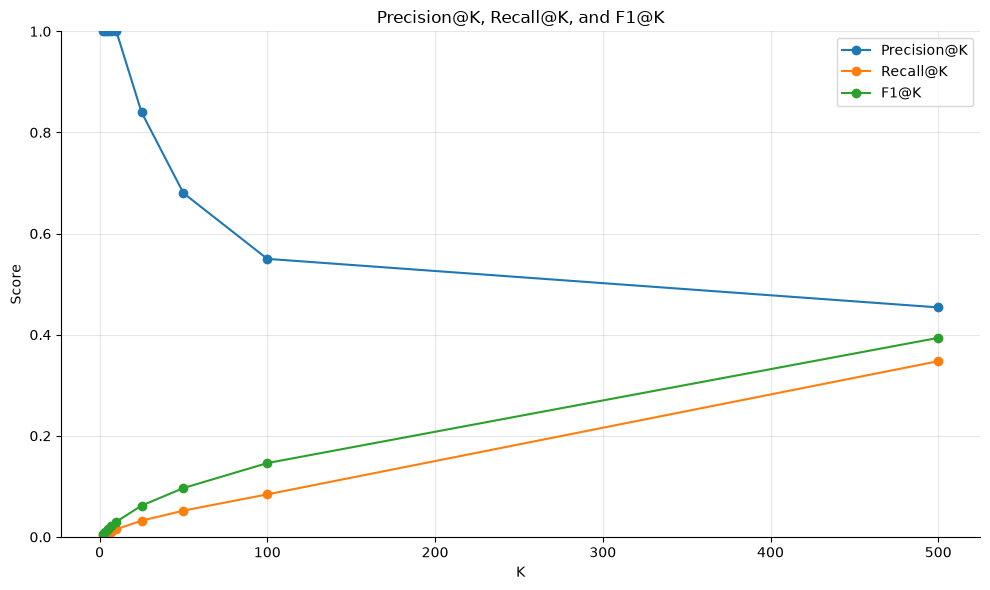

In [62]:

# plotting those results
def plot_k_precision_recall_f1(precisions, recalls, k_values):

    precisions = np.asarray(precisions)
    recalls = np.asarray(recalls)
    k_values = np.asarray(k_values)

    # Calculate F1 for each K
    f1_scores = np.divide(
        2 * precisions * recalls,
        precisions + recalls,
        out=np.zeros_like(precisions, dtype=float),
        where=(precisions + recalls) != 0
    )

    plt.figure(figsize=(10, 6))

    plt.plot(k_values, precisions, marker='o', label='Precision@K')
    plt.plot(k_values, recalls, marker='o', label='Recall@K')
    plt.plot(k_values, f1_scores, marker='o', label='F1@K')

    plt.xlabel('K')
    plt.ylabel('Score')
    plt.title('Precision@K, Recall@K, and F1@K')
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
plot_k_precision_recall_f1(K_precisions, K_recalls, k_values)

# Recall@K per chokepoint 

The results for Precision and Recall @ K across all rows in the model data showed similar results to standard metrics. 

For an analyst flagging chokepoints for review, the K value that matters would be chokepoints, because time and resource constraints only allow for evaluation of the most risky routes. Therefore a more useful metric would come from measuring the results of the top K chokepoints. 

The decision of whether to reroute away from risky chokepoints should air on the side of unnecessary reroutes due to false positives, rather than costly and dangerous transits of chokepoints from false negatives, so the metric that is best suited to this is recall. 

Testing different K chokepoint values for best Recall@K gives the following results 

Recall@2 chokepoints: 0.0625
Recall@3 chokepoints: 0.1250
Recall@5 chokepoints: 0.1875
Recall@7 chokepoints: 0.3125
Recall@10 chokepoints: 0.5625
Recall@25 chokepoints: 0.6875
Recall@50 chokepoints: 0.8750


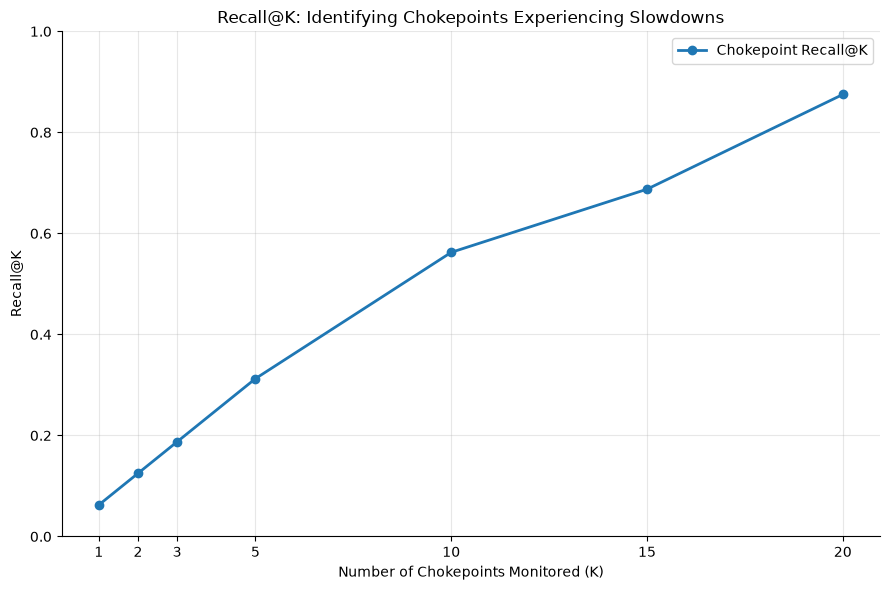

In [63]:
def chokepoint_recall_at_k(
    df,
    y_true,
    y_scores,
    k_values,
    group_col="portid"
):
    results = []

    # Create evaluation dataframe
    evaluation = pd.DataFrame({
        group_col: df[group_col].values,
        "actual": np.asarray(y_true),
        "predicted": np.asarray(y_scores)
    })

    # Aggregate actual slowdowns and predicted risk by chokepoint
    grouped = evaluation.groupby(group_col).agg(
        actual_slowdowns=("actual", "sum"),
        predicted_risk=("predicted", "mean")
    )

    # A chokepoint is considered positive if it experienced
    # at least one actual slowdown during the test period
    grouped["actual_positive"] = (
        grouped["actual_slowdowns"] > 0
    ).astype(int)

    total_positive = grouped["actual_positive"].sum()

    # Rank chokepoints by predicted risk
    grouped = grouped.sort_values(
        "predicted_risk",
        ascending=False
    )

    for k in k_values:

        top_k = grouped.head(k)

        true_positives = top_k["actual_positive"].sum()

        recall = (
            true_positives / total_positive
            if total_positive > 0 else 0
        )

        results.append(recall)

    return results, grouped

k_cp_values = [1, 2, 3, 5, 10, 15, 20]

chokepoint_recalls, chokepoint_ranking = chokepoint_recall_at_k(
    model_data.loc[test],
    y_test,
    probabilities,
    k_cp_values
)

for k, recall in zip(k_values, chokepoint_recalls):
    print(f"Recall@{k} chokepoints: {recall:.4f}")

def plot_chokepoint_recall_k(recalls, k_values):

    plt.figure(figsize=(9, 6))

    plt.plot(
        k_values,
        recalls,
        marker='o',
        linewidth=2,
        label='Chokepoint Recall@K'
    )

    plt.xlabel('Number of Chokepoints Monitored (K)')
    plt.ylabel('Recall@K')
    plt.title('Recall@K: Identifying Chokepoints Experiencing Slowdowns')

    plt.xticks(k_values)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_chokepoint_recall_k(chokepoint_recalls, k_cp_values)


## Data Block Bootstrap 

Bootstrapping time series data requires specific methods that preserve chronological order, and simulate a resample from time-blocked segments of the data instead. For this experiment bootstrap was used to calculate Confidence Intervals and measure uncertainty. 

### Uncertainty

Using a function that generates Block Bootstrap over the test set, we resample the test set many times to approximate the true distribution of traffic for each stretch of history, calculate the CI, and measure how much the test sets AP value depends on the time period from which it was sampled. 

## Procedure 

Let $\mathcal{T}_{\text{test}} = (t-1 \dots t_n)$ be the ordered set of unique test dates. Then for each of $B$ resamples $b = 1, \dots, B$ of block length $L$ , do 

1. Draw $\lceil n / L \rceil$ starting points $s_1, \dots$ uniformly from dates $1, \dots, n$. 
2. For each start date $s_i$ capture the following $L$ consecutive dates $t_s, \dots, t_{s+L}$. For the end of the series dates wrap around to the beginning. 
3. Concatenate all block samples and limit to $n$ total dates. 
4. Take all chokepoint rows for each date, preserving cross-chokepoint dependence. 
5. Compute Average Precision for each method on the resampled rows: $\hat\theta^{*}_{b}$. 

We choose $L = 35$ days to accomodate the 28 day baseline period and 7 day forecast period.  

**check for validity**
The bootstrap process is resampling form **evaluation rows**, not refitting the model to each concatenated set of resampled block data. Features and model fit are from the real series. Since features are time dependent and chronological order is a factor, anything calculated form the stitched together resamples would be invalid. We can still use this to approximate traffic distributions for the sampled time windows. 
**end check for validity**

# Analyzing bootstrap results 

For each evaluation method we compute the Confidence Interval 

$$
\big[\hat\theta^{*}_{(0.025)}, \ \hat\theta^{*}_{(0.5)}, \ \hat\theta^{*}_{(0.975)}\big]
$$

Which is the 2.5th, 50th, and 97.5th percetile of $\{\hat\theta^{*}_b\}_{b=1}^{B}$

To compare evaluation method $m$ with a baseline reference $m_0$ (for example, comparing Logistic Regression against Persistance) we used **paired difference**, which tests each method against each other method. 

$$
\Delta_b = \hat\theta^{*}_{m, b} - \hat\theta^{*}_{m_0, b}, \qquad \widehat{P}(m > m_0) = \frac{1}{B}\sum_{b=1}^{B}[\Delta_b > 0]
$$

The benefit of this is that pairing cancels out variation shared by both methods, since a difficult split to model is difficult for both methods, so the resulting interval for $\Delta$ is tighter than each method suggests separately. 

If the 95% interval for $\Delta$ excludes zero, that suggests the difference is unlikely to be explained by the choice of test dates alone. And equally if the interval *does* include 0, we cannot say for sure that the model is learining anything more than random chance. 

Resamples that have no positive-target rows are skipped because Average Precision is undefined for those rows. 



In [64]:

#bootstrapping the time series data 

def date_block_bootstrap(dates, y, scores, block_len=35, n_boot=1000, seed=42):

    rng = np.random.default_rng(seed)
    dates = pd.Series(pd.to_datetime(dates)).reset_index(drop=True)
    groups = dates.groupby(dates).indices
    date_rows = [groups[d] for d in sorted(groups)] 
    n_dates = len(date_rows)
    n_blocks = int(np.ceil(n_dates/block_len))

    out = {k: [] for k in scores}
    for _ in range(n_boot):
        starts = rng.integers(0, n_dates, size=n_blocks)
        picked = ((starts[:, None] + np.arange(block_len)) % n_dates).ravel()[:n_dates]
        rows = np.concatenate([date_rows[i] for i in picked])
        yb = y[rows] 
        if yb.sum() == 0:
            continue
        for name, s in scores.items():
            out[name].append(average_precision_score(yb, s[rows]))

    return {k: np.array(v) for k, v in out.items()}

test_dates = model_data.loc[test, "date"].to_numpy()
baseline = (1 - X_test["mean_7day"] / X_test["mean_28day"]).to_numpy()

res = date_block_bootstrap(test_dates, y_test.to_numpy(), {"logreg": probabilities, "persistence": baseline})

for k, v in res.items():
    print(k, np.percentile(v, [2.5, 50, 97.5]).round(3))

diff = res["logreg"] - res["persistence"]
print("Model - Baseline AP: ", np.percentile(diff, [2.5, 50, 97.5]).round(3))

logreg [0.262 0.383 0.508]
persistence [0.182 0.274 0.383]
Model - Baseline AP:  [-0.071  0.108  0.266]


## First bootstrap (single 2025 test window) results 

On the single test window, the logistic regressoin had a median AP of 0.38, which is higher than the persistence score of 0.27. Both are significantly above the prior baseline of 0.036. However, the paired difference has a median of +0.11 and a 95\% interval of $[-0.071,  0.108,  0.266] which includes zero. One test winow alone is not enough to confirm that the model beats the persistence rule, as this result might depend on that 2025 cutoff. 

This result motivated incusion of ratio features, and the walk forward train test split for evaluation on multiple time windows. 



## Adding the Ratio and Calendar Features to Feature Vector

Since the slowdown label is relative, comparing future traffic against a trailing baseline, and therefore specific to each day $t$. Logistic Regression cannot form ratios on its own, so at this point the ratio features outlined in the features section were added to the model data. 

Additionally, seasonal events like Chinese New Year and other holidays could be associated with some fluctuations in traffic, so the calendar features were included as well. 

In [65]:

#calculating ratio features from absolute features 

model_data["ratio_7_28"] = model_data["mean_7day"] / model_data["mean_28day"]
model_data["ratio_lag_28"] = model_data["traffic_lag1"] / model_data["mean_28day"]
model_data["cv_28"] = model_data["std_28day"] / model_data["mean_28day"] 

#adding likely holidays or holiday time periods where slowdown may be expected 

#add day of the week (1-7) and month (1-12) for each day
model_data["dow"] = model_data["date"].dt.dayofweek
model_data["month"] = model_data["date"].dt.month

#and the sin(2*pi*(doy/365.25)) and cos(2*pi*(doy/365.25))
doy = model_data["date"].dt.dayofyear
model_data["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
model_data["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

ratio_cols = ["ratio_7_28", "ratio_lag_28", "cv_28"]
cyc_cols = ["doy_sin", "doy_cos"]

dow_d = pd.get_dummies(model_data["dow"], prefix="dow", dtype=int)
month_d = pd.get_dummies(model_data["month"], prefix="month", dtype=int)

X = pd.concat(
    [model_data[features + ratio_cols + cyc_cols],
     chokepoint_features, dow_d, month_d],
     axis=1,
)

y = model_data["slowdown"].astype(int)


ratio_model = make_pipeline

## Walk-forward train-test splits 

A single test window can only tell us so much about the ability of the model to predict from the data, and the resulting estimate is likely heavily influenced by noise in the data and depends on the selected train test split date. 

For that reason at this point the walk-forward train-test split technique outlined in the procedure section was used to take 9 walk-forward folds. 

Starting every six months from January 1st, 2022 we take a test set for that period, and an expanding training set that includes all earlier data for each test set, with the necessary 7 day gap between the training and test periods. 

The scaler and model are refit in every fold, and out-of-sample predictions from all folds are pooled, with the paired block bootstrap applied to the pooled set. 

In addition to the bootstrap paired difference, a per-fold AP is reported to see if any result depends on a single period. 

In [66]:

#using rolling train test split, like k-fold validation for time series

from sklearn.base import clone

folds = [(s, s + pd.DateOffset(months=6)) for s in pd.date_range("2022-01-01", "2026-01-01", freq="6MS")]

template = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)

rows, pooled = [], [] 
for start, end in folds:
    train_m = model_data["date"] < start - pd.Timedelta(days=7)
    test_m = (model_data["date"] >= start) & (model_data["date"] < end)
    y_te = y[test_m].to_numpy()

    if test_m.sum() == 0 or y_te.sum() == 0:
        continue

    m = clone(template).fit(X[train_m], y[train_m])
    p = m.predict_proba(X[test_m])[:, 1]
    base = (1 - X.loc[test_m, "mean_7day"] / X.loc[test_m, "mean_28day"]).to_numpy()

    rows.append({
        "test_start": start.date(),
        "n_pos": int(y_te.sum()),
        "base_rate": y_te.mean(),
        "ap_logreg": average_precision_score(y_te, p), 
        "ap_persist": average_precision_score(y_te, base),
    })
    pooled.append(pd.DataFrame({
        "date": model_data.loc[test_m, "date"].to_numpy(),
        "y": y_te, "logreg": p, "persist": base,
    }))

fold_df = pd.DataFrame(rows)
print(fold_df.round(3).to_string(index=False))

pooled = pd.concat(pooled, ignore_index=True)
res = date_block_bootstrap(
    pooled["date"].to_numpy(), pooled["y"].to_numpy(),
    {"logreg": pooled["logreg"].to_numpy(), "persistence": pooled["persist"].to_numpy()},
)
diff = res["logreg"] - res["persistence"] 
print("model - baseline AP: ", np.percentile(diff, [2.5, 50, 97.5]).round(3))

test_start  n_pos  base_rate  ap_logreg  ap_persist
2022-01-01     70      0.014      0.412       0.415
2022-07-01    129      0.025      0.426       0.252
2023-01-01    133      0.027      0.546       0.476
2023-07-01    179      0.035      0.451       0.406
2024-01-01    162      0.032      0.662       0.453
2024-07-01    179      0.035      0.363       0.262
2025-01-01    164      0.032      0.414       0.264
2025-07-01    176      0.034      0.437       0.227
2026-01-01    183      0.036      0.345       0.167
model - baseline AP:  [0.081 0.124 0.164]


With ratio and calendar features included, logistic regression beats persistence in 8 of 9 walk forward folds and ties in the ninth fold. Pooled paired-difference is +0.12 AP with a 95\% interval of $[0.081, \ 0.164]$, which excludes zero. 

Both methods are far above the baseline rate (1.4\% to 3.6\%), and AP from persistence declines over time, from 0.42 to 0.17, while the model's AP holds up better. Looking at this pooled metric alone, the model appears to perform clearly better than persistence, but we first need to see where the gain is coming from, and check performance on individual chokepoints. 

## Albation: Feature Groups

To see how much each feature group contributes to the prediction, the walk-forward model is refit on subsets of features: raw traffic levels, ratios, chokepoint one-hot vectors, and calendar features. Each group is tested alone and in combination with each other group. 

In [67]:

#ablation to check feature salience

dates = model_data["date"]
col_groups = {
    "levels": features,
    "ratios": ratio_cols,
    "calendar": cyc_cols + list(dow_d.columns) + list(month_d.columns),
    "chokepoint": list(chokepoint_features.columns),
}

for g, cols in col_groups.items():
    missing = [c for c in cols if c not in X.columns]
    assert not missing, (g, missing)
    print(f"{g:11s} {len(cols):3d} columns")

variants = {
    "levels+chokepoint (orig)": ["levels", "chokepoint"],
    "ratios": ["ratios"],
    "ratios+chokepoint": ["ratios", "chokepoint"],
    "ratios+calendar": ["ratios", "calendar"],
    "ratios+cal+chokepoint": ["ratios", "calendar", "chokepoint"],
    "all": ["levels", "ratios", "calendar", "chokepoint"],
}

def walk_forward(cols, gap_days=7):
    out = []
    for start, end in folds:
        tr = dates < start - pd.Timedelta(days=gap_days)
        te = (dates >= start) & (dates < end)
        if te.sum() == 0 or y[te].sum == 0:
            continue
        m = clone(template).fit(X.loc[tr, cols], y[tr])
        out.append(pd.Series(m.predict_proba(X.loc[te, cols])[:, 1], index=X.index[te]))
    return pd.concat(out)

preds = {name: walk_forward(sum((col_groups[g] for g in gs), []))
         for name, gs in variants.items()}

pooled = pd.DataFrame(preds)
pooled["persistence"] = 1 - X.loc[pooled.index, "mean_7day"] / X.loc[pooled.index, "mean_28day"]

fold_of = pd.Series(pd.NaT, index=X.index, dtype="datetime64[ns]")
for start, end in folds:
    fold_of[(dates >= start) & (dates < end)] = start

rows = []
for start, g in pooled.groupby(fold_of.loc[pooled.index]):
    yy = y.loc[g.index]
    rows.append({"fold": start.date(), "n_pos": int(yy.sum()),
                 **{c: average_precision_score(yy, g[c]) for c in pooled.columns}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

res = date_block_bootstrap(
    dates.loc[pooled.index].to_numpy(),
    y.loc[pooled.index].to_numpy(),
    {k: pooled[k].to_numpy() for k in pooled.columns},
    block_len=35, n_boot=1000, seed=0,
)

def ci(a):
    return np.percentile(a, [2.5, 50, 97.5]).round(3)

print("\nAverage Precision by variant [2.5%, median, 97.5%]")
for k, v in res.items():
    print(f"{k:28s}", ci(v))

print("\nvs persistence: [2.5%, median, 97.5%] P(better)")
for k in preds:
    d = res[k] - res["persistence"]
    print(f"{k:28s}", ci(d), round((d > 0).mean(), 3))

print("\ntargeted comparisons")
for a, b in [("ratios+calendar", "ratios"),
             ("ratios+chokepoint", "ratios"),
             ("ratios+cal+chokepoint", "ratios+calendar"),
             ("all", "ratios+cal+chokepoint")]:
    d = res[a] - res[b]
    print(f"{a} - {b}: ", ci(d), round((d > 0).mean(), 3))
    

levels        4 columns
ratios        3 columns
calendar     21 columns
chokepoint   28 columns
      fold  n_pos  levels+chokepoint (orig)  ratios  ratios+chokepoint  ratios+calendar  ratios+cal+chokepoint   all  persistence
2022-01-01     70                     0.549   0.385              0.415            0.383                  0.436 0.412        0.415
2022-07-01    129                     0.298   0.358              0.372            0.406                  0.417 0.426        0.252
2023-01-01    133                     0.403   0.596              0.631            0.590                  0.569 0.546        0.476
2023-07-01    179                     0.272   0.485              0.502            0.521                  0.554 0.451        0.406
2024-01-01    162                     0.671   0.607              0.625            0.653                  0.658 0.662        0.453
2024-07-01    179                     0.198   0.326              0.356            0.327                  0.377 0.363        

From these results, we can see that Ratio features account for the gain. Using only the three ratio features, model beats persistence by +0.148 AP, with the 95% interval above zero of $[0.103, \ 0.189]$. 

The original model with raw levels plus chokepoint dummies is indistinguishable from persistence with a gain of +0.032 AP, and confidence interval of $[-0.048, \ 0.117]$ including zero. Per-fold AP also varies significantly, from 0.2 to 0.67, since the raw traffic levels drift over time while the ratios remain scaled and consistent. 

## Ablation within Ratio Features

The ratio feature group performed the best, so an additional ablation is performed on just these features to see how much each is contributing. 

Features: $r^{(7/28)}$ alone, then with $r^{L}$, then with $\mathrm{cv}$, and then all three. 

Logistig regression using only $r^{(7/28)}$, the ratio of seven day mean to the 28 day baseline mean ranks rows the same as Persistence within a fold, making it a calibrated version of persistnce and a fair baseline for each added feature. 

These targeted comparisons ask whether yesterdays ratio or volatility adds any performance over $r^{(7/28)}$ alone. 

In [68]:

#ablation within ratios
col_groups.update({"r_7_28": ["ratio_7_28"], "r_lag": ["ratio_lag_28"], "r_cv": ["cv_28"]})
variants = {
    "7_28 only": ["r_7_28"],
    "7_28 + lag": ["r_7_28", "r_lag"],
    "7_28 + cv": ["r_7_28", "r_cv"],
    "all three ratios": ["r_7_28", "r_lag", "r_cv"]
}

preds = {name: walk_forward(sum((col_groups[g] for g in gs), []))
         for name, gs in variants.items()}

pooled = pd.DataFrame(preds)
pooled["persistence"] = 1 - X.loc[pooled.index, "mean_7day"] / X.loc[pooled.index, "mean_28day"]

rows = [] 
for start, g in pooled.groupby(fold_of.loc[pooled.index]):
    yy = y.loc[g.index]
    rows.append({"fold": start.date(), "n_pos": int(yy.sum()),
                 **{c: average_precision_score(yy, g[c]) for c in pooled.columns}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

res = date_block_bootstrap(
    dates.loc[pooled.index].to_numpy(),
    y.loc[pooled.index].to_numpy(),
    {k: pooled[k].to_numpy() for k in pooled.columns},
    block_len=35, n_boot=1000, seed=0
)

print("\nAverage Precision by variant [2.5%, median, 97.5%]")
for k, v in res.items():
    print(f"{k:20s}", ci(v))

print("\nvs Persistance")
for k in preds:
    d = res[k] - res["persistence"]
    print(f"{k:20s}", ci(d), round((d > 0).mean(), 3))

print("\nTargeted Comparisons")
for a, b, in [("7_28 only", "persistence"),
                ("7_28 + lag", "7_28 only"),
                ("7_28 + cv", "7_28 only"),
                ("all three ratios", "7_28 only"),
                ("all three ratios", "7_28 + lag"),
                ("all three ratios", "7_28 + cv"),
                ]:
    d = res[a] - res[b]
    print(f"{a} - {b}:", ci(d), round((d > 0).mean(), 3))

      fold  n_pos  7_28 only  7_28 + lag  7_28 + cv  all three ratios  persistence
2022-01-01     70      0.415       0.435      0.388             0.385        0.415
2022-07-01    129      0.252       0.254      0.359             0.358        0.252
2023-01-01    133      0.476       0.486      0.588             0.596        0.476
2023-07-01    179      0.406       0.390      0.492             0.485        0.406
2024-01-01    162      0.453       0.456      0.609             0.607        0.453
2024-07-01    179      0.262       0.262      0.328             0.326        0.262
2025-01-01    164      0.264       0.266      0.446             0.446        0.264
2025-07-01    176      0.227       0.242      0.391             0.395        0.227
2026-01-01    183      0.167       0.169      0.372             0.379        0.167

Average Precision by variant [2.5%, median, 97.5%]
7_28 only            [0.24  0.307 0.381]
7_28 + lag           [0.252 0.321 0.394]
7_28 + cv            [0.373 0.444 0.

Within the ratio features only, volatility ($\mathrm{cv}$) is responsible for essentially all of the gain. 

The single-feature model with only $r^{(7/28)}$ is indistinguishable from persistence with a gain of only +0.010 and CI of $[-0.006, \ 0.029]$, which includes zero by a small margin. This is expected since it ranks rows within a fold the same way. 

Adding yesterdays ratio $r^{L}$ helps slightly, but addint volatility $\mathrm{cv}$ improves AP by +0.138 with the CI above zero of $[0.092, \ 0.177]$. It also beats persistence in 8 of the 9 folds. 

Once we include volatility ($\mathrm{cv}$) the other two ratios add nothing. 

## Assessing where positives and model Gain comes from 

The ablation of ratio features attributes the gain in performance to $\mathrm{cv}$, which measures the volatility relative to level. In order to see what it detects, we look at the pooled out-of-sample (oos) predicions and break them down by chokepoint to see: number and rate of positives, and the AP score for Persistence vs the model within each chokepoint. 

Additionally, subsets with a minimum mean traffic of at least 10, 20, or 40 ships/day are re-evaluated to see if the performance gain survives when the lowest traffic series are excluded. 

Pooled AP weights the chokepoints by their number of positive targets (slowdowns), so it is possible for a few chokepoints with low traffic to dominate the score. 

In [69]:

# assessing model gains with out of sample pooled predictions
cp_mean = daily_chkpnt.groupby("portid")["n_total"].mean()
oos = pooled.copy()
oos["y"] = y.loc[oos.index]
oos["portid"] = model_data.loc[oos.index, "portid"]
oos["name"] = model_data.loc[oos.index, "portname"]

rows = []
for pid, g in oos.groupby("portid"):
    has_pos = g["y"].sum() > 0
    rows.append({
        "chokepoint": g["name"].iloc[0],
        "mean_traffic": round(cp_mean[pid], 1),
        "n_pos": int(g["y"].sum()),
        "pos_rate": round(g["y"].mean(), 3),
        "ap_persist": average_precision_score(g["y"], g["persistence"]) if has_pos else np.nan,
        "ap_7_28+cv": average_precision_score(g["y"], g["7_28 + cv"]) if has_pos else np.nan,
    })
by_cp = pd.DataFrame(rows).sort_values("mean_traffic")
print(by_cp.round(3).to_string(index=False))

for min_traffic in [10, 20, 40]:
    big = cp_mean[cp_mean >= min_traffic].index
    m = oos["portid"].isin(big).to_numpy()
    r = date_block_bootstrap(
        dates.loc[oos.index][m].to_numpy(), oos["y"].to_numpy()[m],
        {k: oos[k].to_numpy()[m] for k in ["persistence", "7_28 + cv"]},
        block_len=35, n_boot=500, seed=0
    )

    d = r["7_28 + cv"] - r["persistence"]
    print(f">= {min_traffic} ships/day: {len(big)} chokepoints, ",
          f"AP persist {np.median(r["persistence"]):.3f}, cv-model {np.median(r["7_28 + cv"]):.3f}",
          f"diff {ci(d)}")
    

          chokepoint  mean_traffic  n_pos  pos_rate  ap_persist  ap_7_28+cv
       Bering Strait           0.9    631     0.468       0.570       0.603
     Magellan Strait           4.1    105     0.064       0.058       0.049
       Torres Strait           9.1      4     0.002       0.002       0.002
        Mona Passage          10.7      5     0.003       0.004       0.002
      Balabac Strait          10.7     34     0.021       0.057       0.060
        Ombai Strait          11.1      7     0.004       0.003       0.003
    Windward Passage          15.8     12     0.007       0.012       0.006
        Kerch Strait          26.6    386     0.235       0.451       0.365
        Sunda Strait          29.4      0     0.000         NaN         NaN
        Panama Canal          31.1      0     0.000         NaN         NaN
       Lombok Strait          35.8      0     0.000         NaN         NaN
      Mindoro Strait          45.3     13     0.008       0.005       0.007
     Yucatan

The pooled gain does not come from better forecasting within chokepoints. Positives are heavily concentrated and appear to be detecting only noise. The Bering Strait, for example has 46\% of OOS positives with 47\% of its days labeled as slowdowns. 

This is why volatilty was such a productive feature, because in lower traffic chokepoints traffic falls below 70\% of the previous 28 day baseline frequently. 

| Minimum mean traffic | Chokepoints | Persistence AP | Model AP | Difference (95% interval) |
|---|---|---|---|---|
| ≥ 10 ships/day | 25 | 0.240 | 0.278 | +0.038 $[-0.050,\ 0.123]$ |
| ≥ 20 ships/day | 21 | 0.269 | 0.307 | +0.039 $[-0.059,\ 0.133]$ |
| ≥ 40 ships/day | 17 | 0.135 | 0.158 | +0.019 $[-0.023,\ 0.088]$ |


## Comparing withing-chokepoint results with Macro-AP

Since pooled AP can be gamed by the model learining which chokepoints have a high degree of variation or noise, without improving predictions within any one chokepoint, we calcluate the **macro-AP** for chokepoints in each bootstrap sample. 

AP is computed separately for each chokepoint that has at least 15 out-of-sample positives, and then averaged across those chokepoints. 

$$
\textbf{macro-AP} = \frac{1}{|\mathcal{C}^*|} \sum_{c \in \mathcal{C}^*} \mathrm{AP}_c
$$

Resampling uses the same block bootstrap over dates, and once again we calculate the paired difference between each model and the persistence baseline. This is checking whether the model predicts better than persistence *within* a chokepoint.  

In [70]:

#after realizing the prediction was mostly responding to noise, 
#This is a within chokepoint and average bootstrap 

def block_resamples(dates, n_boot=1000, block_len=35, seed=0):
    rng = np.random.default_rng(seed)
    s = pd.Series(pd.to_datetime(dates)).reset_index(drop=True)
    groups = s.groupby(s).indices
    date_rows = [groups[d] for d in sorted(groups)]
    n = len(date_rows)
    nb = int(np.ceil(n / block_len))
    for ii in range(n_boot):
        starts = rng.integers(0, n, size=nb)
        picked = ((starts[:, None] + np.arange(block_len)) % n).ravel()[:n]
        yield np.concatenate([date_rows[i] for i in picked])

#the out of sample from the last cell
oos["date"] = dates.loc[oos.index]
methods = ["persistence", "7_28 only", "7_28 + cv"]

positive_by_cp = oos.groupby("portid")["y"].sum()
keep_cp = positive_by_cp[positive_by_cp >= 15].index 
subset = oos[oos["portid"].isin(keep_cp)].reset_index(drop=True)
print("macro-AP chokepoints:", subset["name"].unique().tolist())

yvector, portvector = subset["y"].to_numpy(), subset["portid"].to_numpy()
scores_by_method = {m: subset[m].to_numpy() for m in methods}
out = {m: [] for m in methods}

datevector = subset["date"].to_numpy()

for rows in block_resamples(datevector):
    yboot, pboot = yvector[rows], portvector[rows]
    per_cp_ap = {m: [] for m in methods}
    for pid in keep_cp:
        mask = pboot == pid
        if yboot[mask].sum() == 0:
            continue
        for m in methods:
            per_cp_ap[m].append(
                average_precision_score(
                    yboot[mask], 
                    scores_by_method[m][rows][mask])
                )
    for m in methods:
        out[m].append(np.mean(per_cp_ap[m]))


method_macro_aps = {method: np.array(vector) for method, vector in out.items()}
for m in methods:
    print(f"{m:14s}", ci(out[m]))
for m in ["7_28 only", "7_28 + cv"]:
    diff = method_macro_aps[m] - method_macro_aps["persistence"]
    print(f"{m} - persistence:", ci(diff), round((diff > 0).mean(), 3))







macro-AP chokepoints: ['Tsugaru Strait', 'Luzon Strait', 'Magellan Strait', 'Balabac Strait', 'Bering Strait', 'Kerch Strait', 'Bosporus Strait', 'Strait of Hormuz']
persistence    [0.156 0.219 0.272]
7_28 only      [0.159 0.222 0.275]
7_28 + cv      [0.165 0.215 0.254]
7_28 only - persistence: [-0.002  0.003  0.009] 0.845
7_28 + cv - persistence: [-0.03  -0.004  0.029] 0.409


Within chokepoints, the model shows no advantage over persistence. 

| Method | Macro-AP, median $[2.5\%,\ 97.5\%]$ | Difference vs. persistence | $\widehat{P}(\text{better})$ |
|---|---|---|---|
| Persistence | 0.219 $[0.156,\ 0.272]$ | | |
| $r^{(7/28)}$ only | 0.222 $[0.159,\ 0.275]$ | +0.003 $[-0.002,\ 0.009]$ | 0.85 |
| $r^{(7/28)} + \mathrm{cv}$ | 0.215 $[0.165,\ 0.254]$ | -0.004 $[-0.030,\ 0.029]$ | 0.41 |



# Re calculating Recall@K with ratio features

Results show that the raw traffic levels were too chokepoint dependent to allow the model to learn anything general. With the introduction of scaled (or scale-free) ratio features we reintroduce recall at k, and collect scores for both the LogReg model and Persistence baseline

In [71]:
def recall_at_k(df, score_col, K, seed=0):
    # df: one row per chokepoint-day with columns date, y, <score_col>
    d = df.sample(frac=1, random_state=seed)          # shuffle so ties break randomly
    rank = d.groupby("date")[score_col].rank(method="first", ascending=False)
    sel = rank <= K
    return d.loc[sel, "y"].sum() / d["y"].sum(), d.loc[sel, "y"].mean()   # recall, precision

ev = pd.DataFrame({
    "date": model_data.loc[test, "date"].to_numpy(),
    "y": y_test.to_numpy(),
    "logreg": probabilities,
    "persistence": baseline,
})

recall_k_scores = {"persistence": [], "logreg": []}
more_k_vals = [1,3,5,7,9,11]
for K in more_k_vals:
    for m in ["persistence", "logreg"]:
        r, p = recall_at_k(ev, m, K)
        recall_k_scores[m].append(r)
        print(f"K={K}  {m:12s} recall={r:.3f}  precision={p:.3f}")

K=1  persistence  recall=0.360  precision=0.362
K=1  logreg       recall=0.417  precision=0.419
K=3  persistence  recall=0.527  precision=0.177
K=3  logreg       recall=0.769  precision=0.258
K=5  persistence  recall=0.560  precision=0.113
K=5  logreg       recall=0.858  precision=0.173
K=7  persistence  recall=0.588  precision=0.085
K=7  logreg       recall=0.902  precision=0.130
K=9  persistence  recall=0.611  precision=0.068
K=9  logreg       recall=0.925  precision=0.103
K=11  persistence  recall=0.628  precision=0.057
K=11  logreg       recall=0.943  precision=0.086


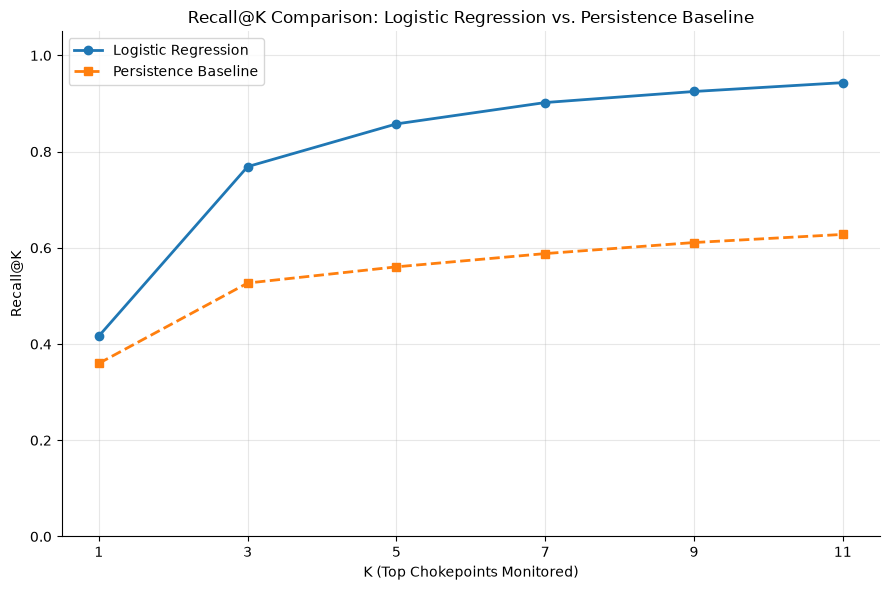

In [72]:
def plot_recall_comparison(k_values, logreg_recalls, persistence_recalls):
    plt.figure(figsize=(9, 6))

    plt.plot(
        k_values,
        logreg_recalls,
        marker='o',
        linewidth=2,
        label='Logistic Regression'
    )
    plt.plot(
        k_values,
        persistence_recalls,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='Persistence Baseline'
    )

    plt.xlabel('K (Top Chokepoints Monitored)')
    plt.ylabel('Recall@K')
    plt.title('Recall@K Comparison: Logistic Regression vs. Persistence Baseline')
    plt.xticks(k_values)
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_recall_comparison(more_k_vals, recall_k_scores["logreg"], recall_k_scores["persistence"])

# Gradient Boosting 

To test the limitations of Logistic Regression for the data, a Gradient Boost model was trained on the complete feature set. SKLearn default uses a held out random set to validate for early stopping, which in time series would break chronological order, so we set ```early_stopping=False```

In [73]:


import itertools
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

dates = model_data["date"]
flex_cols = ratio_cols + cyc_cols + list(chokepoint_features.columns)

# All tuning done inside the locked Training window, Test set is not touched 
val_start = dates[train].max() - pd.Timedelta(days=365)
inner_tr = train & (dates < val_start - pd.Timedelta(days=7))   # 7-day purge again
inner_va = train & (dates >= val_start)

grid = [dict(max_depth=d, learning_rate=lr, max_iter=n, min_samples_leaf=msl)
        for d, lr, n, msl in itertools.product([3, 6], [0.05, 0.1], [100, 300], [50, 200])]

def make_gb(params):
    # early stopping is set to False to avoid sklearn holding out a random test set and breaking time series chronological separation
    return HistGradientBoostingClassifier(**params, class_weight="balanced",
                                          early_stopping=False, random_state=0)

def val_score(params):
    m = make_gb(params).fit(X.loc[inner_tr, flex_cols], y[inner_tr])
    p = m.predict_proba(X.loc[inner_va, flex_cols])[:, 1]
    return average_precision_score(y[inner_va], p)    # swap in your primary metric if you prefer

val_scores = [val_score(p) for p in grid]
best = grid[int(np.argmax(val_scores))]
print("best params:", best, "| validation AP:", round(max(val_scores), 3))

# model refit on full training window
gb = make_gb(best).fit(X.loc[train, flex_cols], y[train])
ev["gb"] = gb.predict_proba(X.loc[test, flex_cols])[:, 1]

# simple model (logreg) on the same split, Ratio features only 
simple = clone(template).fit(X.loc[train, ratio_cols], y[train])
ev["logreg"] = simple.predict_proba(X.loc[test, ratio_cols])[:, 1]

methods = ["persistence", "logreg", "gb"]
for m in methods:
    print(f"{m:12s} AP = {average_precision_score(ev['y'], ev[m]):.3f}")
for K in [1, 3, 5]:
    for m in methods:
        r, p = recall_at_k(ev, m, K)
        print(f"K={K}  {m:12s} recall={r:.3f}  precision={p:.3f}")

# date_block_bootstrap for Confidence Intervals
res = date_block_bootstrap(ev["date"].to_numpy(), ev["y"].to_numpy(),
                           {m: ev[m].to_numpy() for m in methods})
for m in ["logreg", "gb"]:
    d = res[m] - res["persistence"]
    print(f"{m} - persistence:", ci(d), round((d > 0).mean(), 3))
d = res["gb"] - res["logreg"]
print("gb - logreg:", ci(d), round((d > 0).mean(), 3))

best params: {'max_depth': 3, 'learning_rate': 0.1, 'max_iter': 300, 'min_samples_leaf': 50} | validation AP: 0.535
persistence  AP = 0.278
logreg       AP = 0.438
gb           AP = 0.415
K=1  persistence  recall=0.360  precision=0.362
K=1  logreg       recall=0.505  precision=0.508
K=1  gb           recall=0.513  precision=0.516
K=3  persistence  recall=0.527  precision=0.177
K=3  logreg       recall=0.824  precision=0.276
K=3  gb           recall=0.804  precision=0.270
K=5  persistence  recall=0.560  precision=0.113
K=5  logreg       recall=0.882  precision=0.178
K=5  gb           recall=0.888  precision=0.179
logreg - persistence: [0.095 0.163 0.219] 1.0
gb - persistence: [0.069 0.142 0.207] 0.999
gb - logreg: [-0.07  -0.021  0.032] 0.212


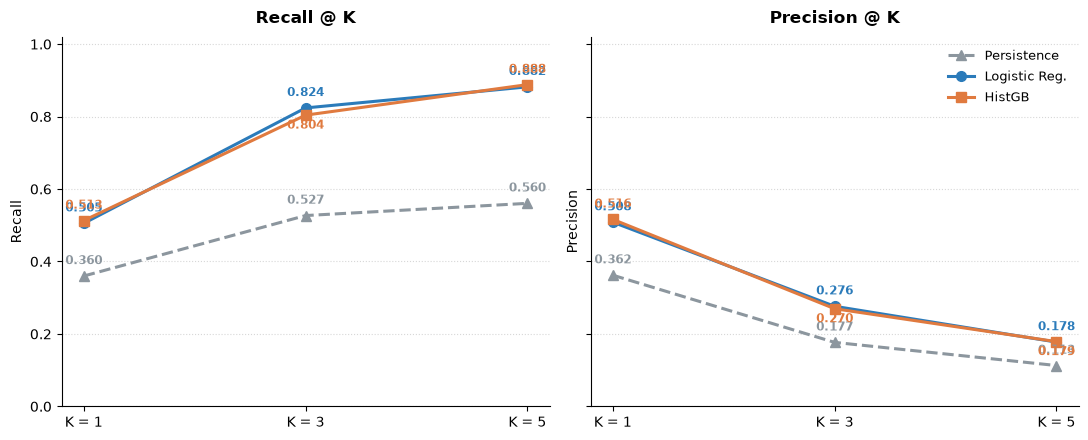

In [74]:

import matplotlib.pyplot as plt

def plot_topk_metrics(ev, recall_at_k, models=("logreg", "gb"), ks=(1, 3, 5), include_persistence=True):
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
    
    plot_methods = (["persistence"] if include_persistence else []) + list(models)
    styles = {
        "persistence": {"label": "Persistence", "color": "#8c969e", "ls": "--", "marker": "^"},
        "logreg":      {"label": "Logistic Reg.", "color": "#2b7bba", "ls": "-",  "marker": "o"},
        "gb":          {"label": "HistGB",        "color": "#e07a3f", "ls": "-",  "marker": "s"},
    }

    fig, (ax_rec, ax_prec) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

    for m in plot_methods:
        st = styles.get(m, {"label": m, "color": None, "ls": "-", "marker": "o"})
        scores = [recall_at_k(ev, m, k) for k in ks]
        recalls = [s[0] for s in scores]
        precs   = [s[1] for s in scores]

        # Left panel: Recall@K
        ax_rec.plot(ks, recalls, label=st["label"], color=st["color"],
                    linestyle=st["ls"], marker=st["marker"], linewidth=2.2, markersize=7)
        for k, r in zip(ks, recalls):
            offset = -0.045 if (m == "gb" and k == 3) else 0.025  # prevents label overlap at K=3
            ax_rec.text(k, r + offset, f"{r:.3f}", ha="center", va="bottom",
                        fontsize=8.5, color=st["color"], fontweight="bold")

        # Right panel: Precision@K
        ax_prec.plot(ks, precs, label=st["label"], color=st["color"],
                     linestyle=st["ls"], marker=st["marker"], linewidth=2.2, markersize=7)
        for k, p in zip(ks, precs):
            offset = -0.045 if (m == "gb" and k in (3, 5)) else 0.025
            ax_prec.text(k, p + offset, f"{p:.3f}", ha="center", va="bottom",
                         fontsize=8.5, color=st["color"], fontweight="bold")

    for ax, title, ylabel in [
        (ax_rec,  "Recall @ K",    "Recall"),
        (ax_prec, "Precision @ K", "Precision"),
    ]:
        ax.set_xticks(ks)
        ax.set_xticklabels([f"K = {k}" for k in ks])
        ax.set_ylim(0, 1.02)
        ax.set_ylabel(ylabel)
        ax.set_title(title, fontweight="bold", pad=10)
        ax.grid(axis="y", linestyle=":", alpha=0.5)

    ax_prec.legend(frameon=False, loc="upper right", fontsize=9.5)
    plt.tight_layout()
    plt.show()

#final results of simple and flexible model against persistence 
plot_topk_metrics(ev, recall_at_k, models=("logreg", "gb"), include_persistence=True)

In [75]:
def walk_forward_model(model, cols, gap_days=7):
    out = []
    for start, end in folds:
        tr = dates < start - pd.Timedelta(days=gap_days)
        te = (dates >= start) & (dates < end)
        if te.sum() == 0 or y[te].sum() == 0:
            continue
        m = clone(model).fit(X.loc[tr, cols], y[tr])
        out.append(pd.Series(m.predict_proba(X.loc[te, cols])[:, 1], index=X.index[te]))
    return pd.concat(out)

preds_gb = walk_forward_model(make_gb(best), flex_cols)

In [76]:
ev["portid"] = model_data.loc[test, "portid"].to_numpy()
ev["name"]   = model_data.loc[test, "portname"].to_numpy()
assert len(ev) == 18156 and ev["y"].sum() == 653

In [77]:

d = ev.sample(frac=1, random_state=0)
d["rank"] = d.groupby("date")["logreg"].rank(method="first", ascending=False)
print(d[d["rank"] <= 3].groupby("name").size().sort_values(ascending=False).head(6))
print(ev.groupby("name")["y"].sum().sort_values(ascending=False).head(5))

name
Bering Strait       605
Kerch Strait        470
Magellan Strait     410
Strait of Hormuz    207
Balabac Strait       77
Ombai Strait         43
dtype: int64
name
Bering Strait       261
Kerch Strait        192
Strait of Hormuz     93
Magellan Strait      34
Balabac Strait       15
Name: y, dtype: int64


In [78]:
K = 3
d = ev.sample(frac=1, random_state=0)                      # random tie-breaking
rank = d.groupby("date")["logreg"].rank(method="first", ascending=False)
ev["flag"] = (rank <= K).reindex(ev.index).astype(int)

train_mean = model_data.loc[train].groupby("portid")["n_total"].mean()   # training window only
ev["tier"] = pd.cut(ev["portid"].map(train_mean), [-np.inf, 10, 40, np.inf],
                    labels=["<10", "10-40", ">40"]).astype(str)
ev["period"] = ev["date"].dt.year.astype(str) + "-H" + np.where(ev["date"].dt.month <= 6, "1", "2")

def slice_table(col, n_boot=1000):
    y, f, s, dts = ev["y"].to_numpy(), ev["flag"].to_numpy(), ev[col].to_numpy(), ev["date"].to_numpy()
    levels = sorted(pd.unique(s))
    draws = {lv: [] for lv in levels}
    for rows in block_resamples(dts, n_boot=n_boot):
        yb, fb, sb = y[rows], f[rows], s[rows]
        for lv in levels:
            m = (sb == lv) & (yb == 1)
            if m.any():
                draws[lv].append(fb[m].mean())             # recall within the slice
    out = []
    for lv in levels:
        in_s = s == lv
        pos = in_s & (y == 1)
        lo, hi = np.percentile(draws[lv], [2.5, 97.5]) if draws[lv] else (np.nan, np.nan)
        out.append({"slice": lv, "n_rows": int(in_s.sum()), "n_pos": int(pos.sum()),
                    "recall": f[pos].mean() if pos.any() else np.nan, "lo": lo, "hi": hi})
    return pd.DataFrame(out)

print(slice_table("tier").round(3).to_string(index=False))
print(slice_table("period").round(3).to_string(index=False))

slice  n_rows  n_pos  recall    lo    hi
10-40    5181    223   0.780 0.616 0.900
  <10    1942    295   0.966 0.923 0.994
  >40   11033    135   0.585 0.253 0.856
  slice  n_rows  n_pos  recall    lo    hi
2025-H1    5063    164   0.909 0.847 0.984
2025-H2    5152    176   0.597 0.520 0.800
2026-H1    5068    183   0.869 0.811 0.942
2026-H2    2873    130   0.962 0.779 1.000


In [79]:
# 1. share of the 3 alert slots going to each tier, and flag rate within tier
print(ev.loc[ev["flag"] == 1, "tier"].value_counts(normalize=True).round(3))
print(ev.groupby("tier")["flag"].mean().round(3))

# 2. which chokepoints are in the <10 tier, and who supplies the >40 positives
print(ev[ev["tier"] == "<10"]["name"].unique())
print(ev[(ev["tier"] == ">40") & (ev["y"] == 1)].groupby("name").size().sort_values(ascending=False).head(8))

# 3. is the period effect just tier mix?
print(pd.crosstab(ev["period"], ev["tier"], values=ev["y"], aggfunc="sum"))

# 4. the fair headline: drop the <10 tier from the alert universe and re-rank
univ = ev[ev["tier"] != "<10"].copy()
for m in ["persistence", "logreg", "gb"]:
    d = univ.sample(frac=1, random_state=0)
    r = d.groupby("date")[m].rank(method="first", ascending=False)
    univ["f"] = (r <= 3).reindex(univ.index).astype(int)
    print(f"{m:12s} recall={univ.loc[univ.y == 1, 'f'].mean():.3f}  precision={univ.loc[univ.f == 1, 'y'].mean():.3f}")

tier
<10      0.541
10-40    0.325
>40      0.134
Name: proportion, dtype: float64
tier
10-40    0.122
<10      0.543
>40      0.024
Name: flag, dtype: float64
<StringArray>
['Torres Strait', 'Magellan Strait', 'Bering Strait']
Length: 3, dtype: str
name
Strait of Hormuz        93
Luzon Strait            12
Mindoro Strait           6
Makassar Strait          6
Taiwan Strait            5
Tsugaru Strait           5
Bosporus Strait          5
Bab el-Mandeb Strait     2
dtype: int64
tier     10-40  <10  >40
period                  
2025-H1     48  111    5
2025-H2     49   88   39
2026-H1     38   89   56
2026-H2     88    7   35
persistence  recall=0.603  precision=0.111
logreg       recall=0.793  precision=0.146
gb           recall=0.799  precision=0.147


In [80]:
# recall by period x tier 
pos = ev[ev["y"] == 1]
print(pos.pivot_table(index="period", columns="tier", values="flag", aggfunc="mean").round(2))
print(pos.pivot_table(index="period", columns="tier", values="flag", aggfunc="size"))

# rank on Hormuz positive days
d = ev.sample(frac=1, random_state=0)
d["rank"] = d.groupby("date")["logreg"].rank(method="first", ascending=False)
h = ev[(ev["name"] == "Strait of Hormuz") & (ev["y"] == 1)]
print("Hormuz positive days:", len(h), "| ranked in top 3:", (d.loc[h.index, "rank"] <= 3).mean().round(3))
top = d[(d["rank"] <= 3) & d["date"].isin(h["date"])]
print("slots by tier on those days:\n", (top.groupby("tier").size() / len(h)).round(2))

# static prior baseline, then paired bootstrap in the restricted universe
prior_rate = y[train].groupby(model_data.loc[train, "portid"]).mean()
ev["prior"] = ev["portid"].map(prior_rate).fillna(0) + 1e-6 * ev["persistence"]   # persistence breaks ties

def flags(df, col, K=3, seed=0):
    s = df.sample(frac=1, random_state=seed)
    r = s.groupby("date")[col].rank(method="first", ascending=False)
    return (r <= K).reindex(df.index).astype(int).to_numpy()

univ = ev[ev["tier"] != "<10"].reset_index(drop=True)
y_u, dates_u = univ["y"].to_numpy(), univ["date"].to_numpy()
F = {m: flags(univ, m) for m in ["persistence", "prior", "logreg", "gb"]}

draws = {m: [] for m in F}
for rows in block_resamples(dates_u):
    yb = y_u[rows]
    if yb.sum() == 0:
        continue
    for m, f in F.items():
        draws[m].append(f[rows][yb == 1].mean())
draws = {m: np.array(v) for m, v in draws.items()}

for m in F:
    print(f"{m:12s}", ci(draws[m]))
for a, b in [("logreg", "persistence"), ("logreg", "prior"), ("gb", "logreg")]:
    dd = draws[a] - draws[b]
    print(f"{a} - {b}:", ci(dd), round((dd > 0).mean(), 3))

tier     10-40   <10   >40
period                    
2025-H1   0.79  1.00  0.00
2025-H2   0.43  0.95  0.00
2026-H1   0.71  0.98  0.80
2026-H2   1.00  0.43  0.97
tier     10-40  <10  >40
period                  
2025-H1     48  111    5
2025-H2     49   88   39
2026-H1     38   89   56
2026-H2     88    7   35
Hormuz positive days: 93 | ranked in top 3: 0.849
slots by tier on those days:
 tier
10-40    0.76
<10      1.37
>40      0.87
dtype: float64
persistence  [0.434 0.609 0.754]
prior        [0.472 0.612 0.74 ]
logreg       [0.609 0.799 0.945]
gb           [0.65  0.803 0.921]
logreg - persistence: [0.099 0.189 0.306] 1.0
logreg - prior: [0.018 0.182 0.348] 0.984
gb - logreg: [-0.046  0.004  0.051] 0.534


In [81]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

tr = model_data.loc[train]
prof = tr.groupby("portid").agg(
    log_mean=("n_total", lambda s: np.log1p(s.mean())),
    med_cv=("cv_28", "median"),
    zero_frac=("n_total", lambda s: (s == 0).mean()),
)
Z = StandardScaler().fit_transform(prof)
for k in [2, 3, 4, 5]:
    print(k, round(silhouette_score(Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z)), 3))

k = 3   # set from the silhouette scores
prof["cluster"] = KMeans(k, n_init=20, random_state=0).fit_predict(Z)
names = model_data.drop_duplicates("portid").set_index("portid")["portname"]
for c, g in prof.groupby("cluster"):
    print(c, names.loc[g.index].tolist())

2 0.809
3 0.575
4 0.567
5 0.571
0 ['Ombai Strait', 'Torres Strait', 'Magellan Strait', 'Windward Passage', 'Mona Passage', 'Balabac Strait', 'Kerch Strait']
1 ['Bering Strait']
2 ['Suez Canal', 'Oresund Strait', 'Taiwan Strait', 'Korea Strait', 'Tsugaru Strait', 'Luzon Strait', 'Lombok Strait', 'Bohai Strait', 'Sunda Strait', 'Panama Canal', 'Makassar Strait', 'Yucatan Channel', 'Mindoro Strait', 'Bosporus Strait', 'Bab el-Mandeb Strait', 'Malacca Strait', 'Strait of Hormuz', 'Cape of Good Hope', 'Gibraltar Strait', 'Dover Strait']


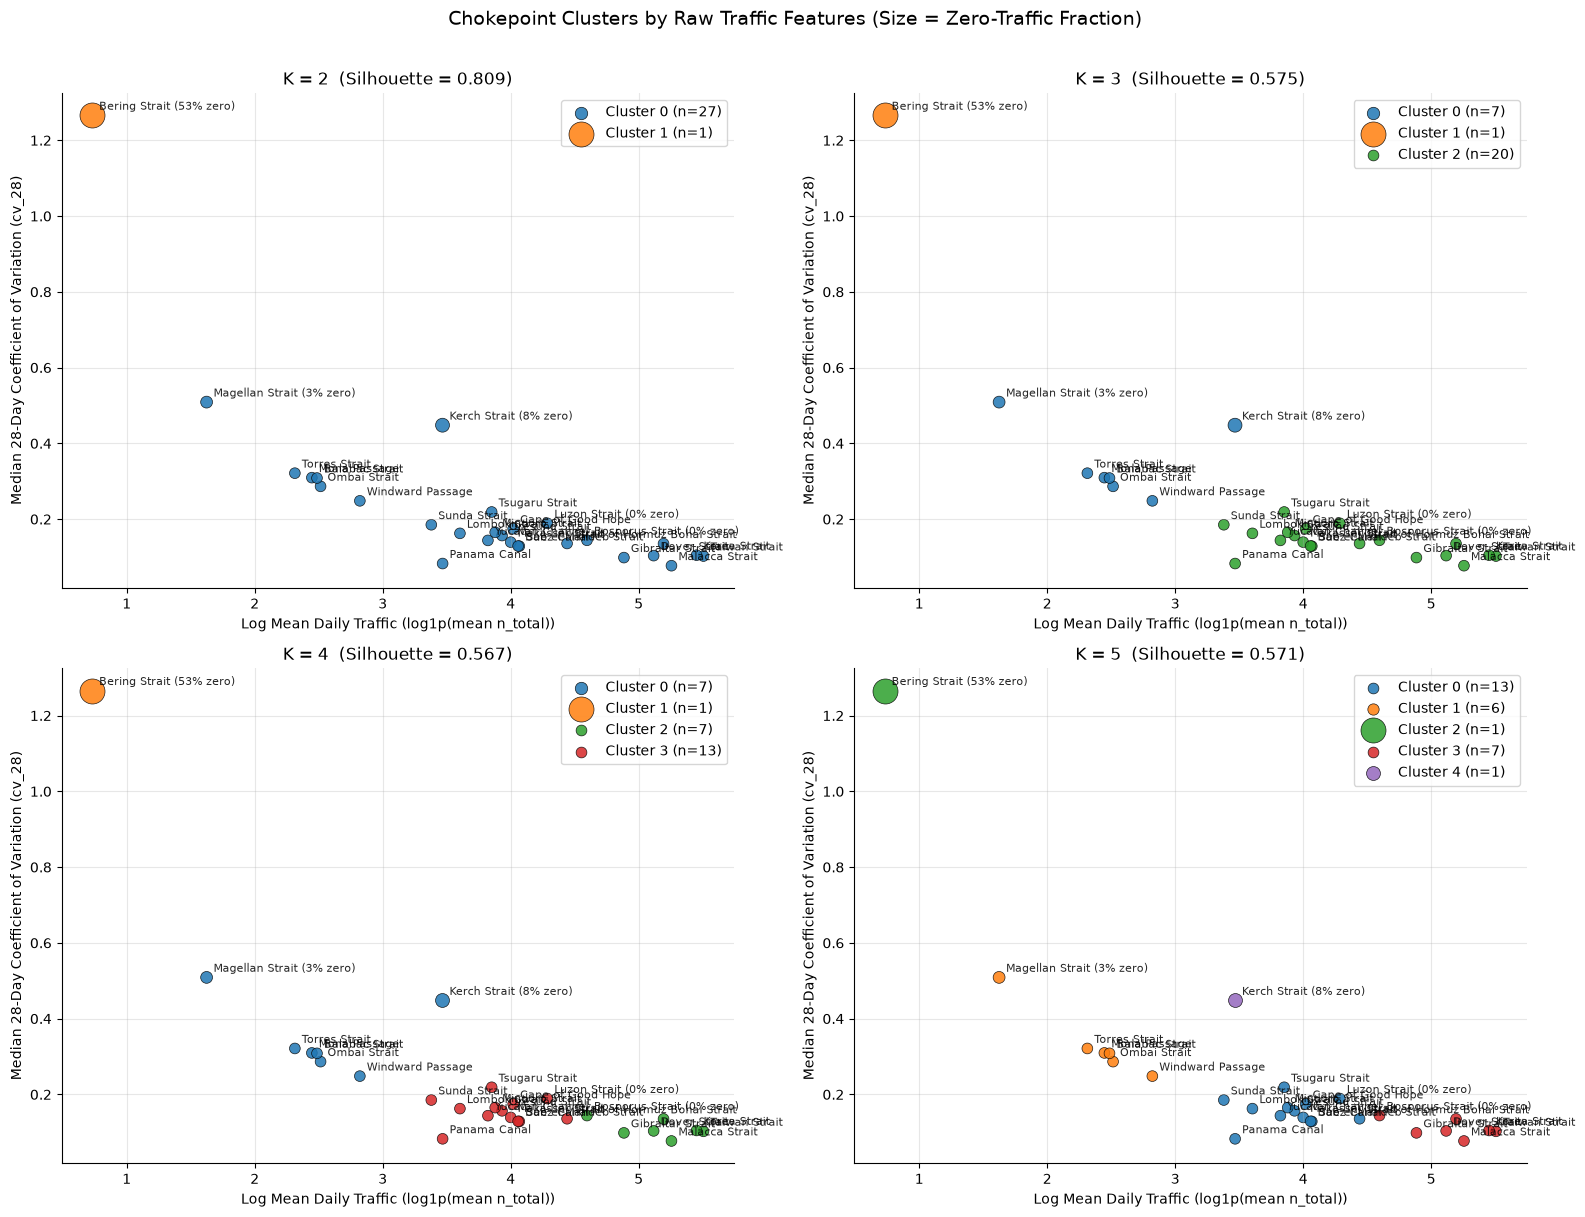

In [82]:
# plotting the K-Means clusters, not with PCA just raw to preserve interpretability. Plotting Log Mean against Mean 28-day COV

# points scaled by their proportion of zero labels, and color coded. 

model_data_copy = model_data.copy()
names = model_data_copy.drop_duplicates("portid").set_index("portid")["portname"].loc[prof.index]

x_vals = prof["log_mean"].values
y_vals = prof["med_cv"].values
zero_vals = prof["zero_frac"].values

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, k in enumerate([2, 3, 4, 5]):
    ax = axes[idx]
    labels = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(Z)
    sil = silhouette_score(Z, labels)

    for c in range(k):
        mask = labels == c
        ax.scatter(
            x_vals[mask],
            y_vals[mask],
            s=60 + 500 * zero_vals[mask],  
            alpha=0.85,
            edgecolors="black",
            linewidth=0.5,
            label=f"Cluster {c} (n={mask.sum()})"
        )

    # Naming the points, their % zero
    for i, name in enumerate(names):
        label_txt = f"{name} ({zero_vals[i]:.0%} zero)" if zero_vals[i] > 0 else name
        ax.annotate(
            label_txt,
            (x_vals[i], y_vals[i]),
            fontsize=8,
            alpha=0.85,
            xytext=(5, 4),
            textcoords="offset points"
        )

    ax.set_title(f"K = {k}  (Silhouette = {sil:.3f})")
    ax.set_xlabel("Log Mean Daily Traffic (log1p(mean n_total))")
    ax.set_ylabel("Median 28-Day Coefficient of Variation (cv_28)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

plt.suptitle("Chokepoint Clusters by Raw Traffic Features (Size = Zero-Traffic Fraction)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [83]:
# original model (raw levels + chokepoint dummies), refit on the locked split
orig_cols = features + list(chokepoint_features.columns)      # 4 levels + 28 dummies
orig = clone(template).fit(X.loc[train, orig_cols], y[train])
ev["orig"] = orig.predict_proba(X.loc[test, orig_cols])[:, 1]

assert len(ev) == 18156, "ev does not match the locked test set"
print("AP =", round(average_precision_score(ev["y"], ev["orig"]), 3), "(expect about 0.381)")
for K in [1, 3, 5]:
    r, p = recall_at_k(ev, "orig", K)
    print(f"K={K}  orig  recall={r:.3f}  precision={p:.3f}")

AP = 0.381 (expect about 0.381)
K=1  orig  recall=0.417  precision=0.419
K=3  orig  recall=0.769  precision=0.258
K=5  orig  recall=0.858  precision=0.173


# Conclusions 

### Overview
Disruption event records proved to be too sparse at chokepoint locatoins to serve as labels for a classifier.Instead, the experiment was to see if daily ship counts at 28 maritime chokepoints was sufficient to forecast traffic slowdowns at those chokepoints, defined as the next 7-day mean falling below 70\% of the trailing 28 day mean used as a baseline.

A leakage-safe panel of past-only features, evaluated with nine walk-forward folds and a 7 day buffer between train and test sets, was fit to the data and evalueated with paired block bootstrap over the dates. 

### Findings 

1. **On pooled Average Precision, ratio features calculated from the 28 day baseline period beat a persistence baseline.** Logistic regression on ratio features imporved on persistence by $\approx +0.015$, while the original model fit with raw traffic levels was indistinguishable from persistence because levels vary over time in a way that ratios do not. 
2. **The gain comes from one feature** Calendar features added nothing to the models predictive ability, and one-hot encoded chokepoint IDs added little. Within the rasio features the volatility measure was responsible for almost all of the improvement. 
3. **The gain does not survive within-chokepoints** Evaluation showed that 3 low traffic or noisy chokepoints (Magellan, Bering, and Kerch) held $\approx 82\%$ of the out-of-sample positives, which is why the volatility feature identified them. High pooled AP scores came from ranking those rows highest. Once AP is averaged within chokepoints, the model performance is no better than persistence. 

Using only its own traffic history, this model shows **no demonstrable advantage over the persistence rule** within chokepoints. 

Both methods rank slowdown days well above chance in certain chokepoints, namely Hormuz, where the persistence rule alone achieved AP of 0.50 compared to a 3.6\% base rate. 

### Limitations 

- **The targets are a statistical construct** Traffic decrease of 30\% or more below baseline is essentially an arbitrary choice, despite some validation against other thresholds, and it is not reasonable to use that same threshold across all chokepoints. For low traffic chokepoints a 30\% drop can result from a relatively small difference in total amount of ships. 
- **Small effective sample size** Positives occur in runs of days, dependent on eachother, so it is the number of slowdowns in the data not the number of rows that dictates how much can be learned. 
- **Evaluation choices were informed by initial tests** Folds were examined while designing features, so the intervals are likely optimistic. Due to limitations in available data, no final untouched holdout was preserved for testing. 
- **Model is univariate and pooled** The model used a single time-series per chokepoint and training was done on all chokepoints at once. 
- **The bootstrap cannot improve predictions** Date-block bootstrapping is limited and could not produce resample data for training, it could only be used for evaluation. Additionally, the bootstrap did not capture variance from model fitting or tuning, and had no access to data outside of the time series. 

### Future work 

- **A noise-aware label.** Slowdowns should be defined in units of each chokepoints specific volatility, so that a 'slowdown' has the same significance across all chokepoints. 
- **Additional features** Including lagged ratios from nearby, upstream or downstream chokepoints in each chokepoint's features, linking available disruption events to ports and by proxy to chokepoints, among other possible features, could improve the model's predictive ability. 
- **Training and Evaluating on well measured chokepoints only** plus a held out final date-range reserved for final testing. 

The main methodological lesson is that a time series dataset such as this requires large amounts of data, and ideally some external data synced with the dates, so that the model is not just predicting traffic from traffic. The only other variable is time, and there are real limitations to how well a model can predict changes in a variable based only on past levels of the same variable. This is made clear by the model performing no better than the persistence rule. 

The most significant takeaway is that using a pooled metric can produce results that disappear on further decomposition. A simple baseline and paired uncertainty estimate was able to expose the models limitations. 



In [84]:
model_data.to_csv("data/final_feature_vector.csv", index=False)

# Headline Result 

The final cell below reproduces the headline result from the code 

In [85]:
# Reproduce the headline result: logistic regression vs. persistence

assert len(ratio_cols) == 3, f"Expected 3 ratio features, found {len(ratio_cols)}"

logreg_recall, _ = recall_at_k(ev, "logreg", K=3)
persistence_recall, _ = recall_at_k(ev, "persistence", K=3)

print(
    f"Logistic regression fit on 3 ratio features achieved "
    f"\nRecall@3 score of {logreg_recall:.3f} against a "
    f"\npersistence baseline of {persistence_recall:.3f}."
)

Logistic regression fit on 3 ratio features achieved 
Recall@3 score of 0.824 against a 
persistence baseline of 0.527.
